<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [1]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
import Models
import utils as utils
import torch
import matplotlib.pyplot as plt
import os
import random
import datetime
import importlib
importlib.reload(utils)
importlib.reload(Models)

Not running in Google Colab


<module 'Models' (namespace) from ['c:\\Users\\bar24\\OneDrive - Universiteit Utrecht\\Documents\\School\\UU Data Sceince MSc\\1st Year\\Period 4\\Deep learning (INFOMDLR)\\Assignments\\Deep_Learning_MEG\\Models']>

## Global Definitions

In [2]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"
output_dir = "./Output"
model_dir = "./Models"

# check if outpiut directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# check if model directory exists
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

debug_mode = False

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# model and data related parameters
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL # Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "cross"  # or "cross"
downsample = True  # or False
downsample_rate = 0  
if downsample:
    downsample_rate = 7

### Check if we are in google colab then we need to mount the drive

In [3]:
# If we are in colab and we need to mount the drive
if is_colab():
  from google.colab import drive
  # Mount Google Drive
  drive.mount('/content/drive')
  print("Google Drive mounted successfully.")
  data_dir = f"{google_drive_folder}/Final Project data"
else:
  print("Not in Google Colab.")

Not in Google Colab.


### Check if we have cude

In [4]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.5.1
None
90100
True


### Extract the Zip File

In [5]:
import zipfile

# Check if the dataset is already extracted, if not extract it
if not os.path.exists(data_dir):
    print("Extracting the dataset...")
    #unzip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    #list files in the extracted dir
    os.listdir(data_dir)
else:
    print("Dataset already extracted.")

Dataset already extracted.


### Load one example

Matrix shape: (248, 35624)


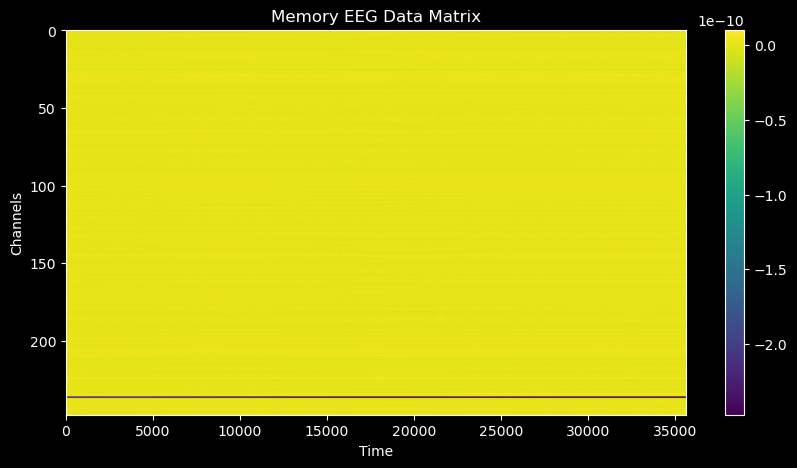

Matrix shape: (248, 35624)


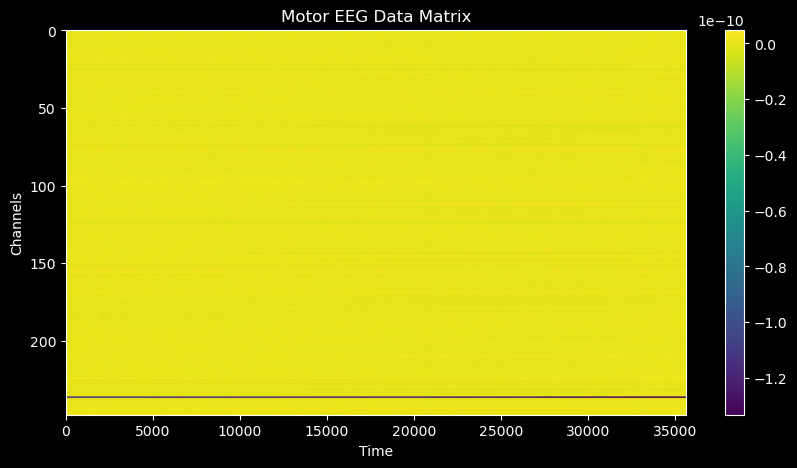

Matrix shape: (248, 35624)


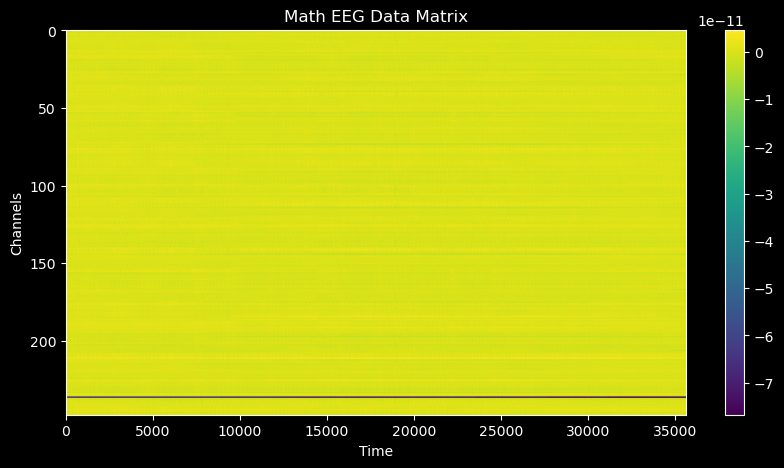

Matrix shape: (248, 35624)


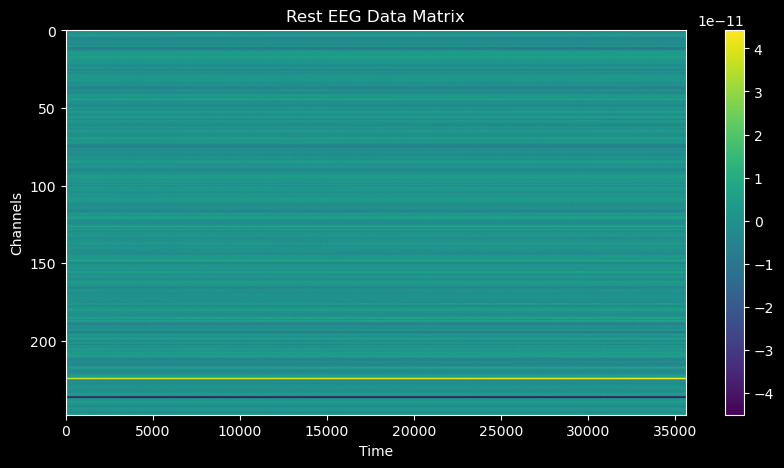

In [6]:
## peak into a matrix to see the data
matrix = utils.get_dataset_from_h5py(f"{data_dir}/Cross/train/task_working_memory_164636_3.h5")
if matrix is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Memory EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

## peak into a matrix to see the data
matrix_motor = utils.get_dataset_from_h5py(f"{data_dir}/Cross/train/task_motor_164636_3.h5")
if matrix_motor is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix_motor, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Motor EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

## peak into a matrix to see the data
matrix_math = utils.get_dataset_from_h5py(f"{data_dir}/Cross/train/task_story_math_164636_3.h5")
if matrix_math is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix_math, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Math EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

matrix_rest = utils.get_dataset_from_h5py(f"{data_dir}/Cross/train/rest_164636_3.h5")
if matrix_rest is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix_rest, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Rest EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

### Load the datasets

In [7]:
train_data, train_df, test_data, test_df = utils.load_dataset(
    which_dataset=which_dataset,
    data_dir=data_dir,
    scaler_type=scaler_type,
    downsample_rate=downsample_rate
)

Loading cross dataset...
Loading cached: Data\Normalized\z_score_local\cross_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test1_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test2_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test3_scaled.pt
Data for dataset cross was loaded successfully


### Definitions for training and logging

In [8]:
# Check if the data is loaded correctly
print("train task types counts:")
print(np.bincount(train_df['task_type'].astype('category').cat.codes))
print("test task types counts:")
print(np.bincount(test_df['task_type'].astype('category').cat.codes))


timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
# Set this once at the top of your notebook/cell
MODEL_NAME = utils.ModelClass.__name__ # "MEGClassifier"
print(f"Using model class: {MODEL_NAME}")
model_name = f"{MODEL_NAME}_{which_dataset}"
model_pth_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.pth"
model_csv_path = f"{output_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.csv"
model_json_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.json"
best_model = None

# create folders if they do not exist
if not os.path.exists(f"{model_dir}/{which_dataset}"):
    os.makedirs(f"{model_dir}/{which_dataset}")


if not os.path.exists(f"{output_dir}/{which_dataset}"):
    os.makedirs(f"{output_dir}/{which_dataset}")

train task types counts:
[16 16 16 16]
test task types counts:
[12 12 12 12]
Using model class: MultiviewAttention


In [9]:
data_first = train_data[0]
data_first.shape

torch.Size([248, 5089])

### Training stage #1 - fine-tuning using cross validation and optuna

[I 2025-06-05 10:03:11,258] A new study created in memory with name: no-name-9319066c-c518-4a6a-8386-006f5f2b17f0
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 1, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\utils.py:785: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_metrics_df = pd.concat([all_metrics_df, pd.DataFrame([row])], ignore_index=True)


Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 1, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 1, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 1, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


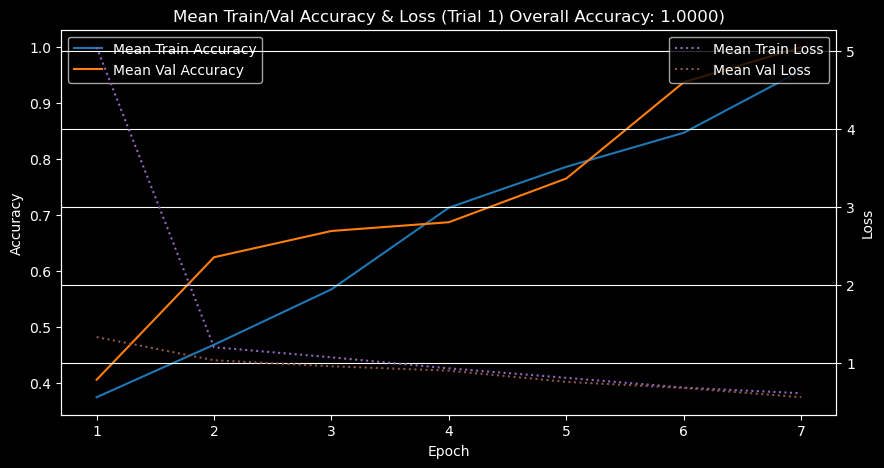

[I 2025-06-05 10:04:13,228] Trial 0 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.001100064262601451, 'batch_size': 8, 'dropout_rate': 0.25, 'optimizer': 'adam', 'weight_decay': 3.631206859671725e-07, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 0 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9642437994480133


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 2, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 2, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 2, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 2, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


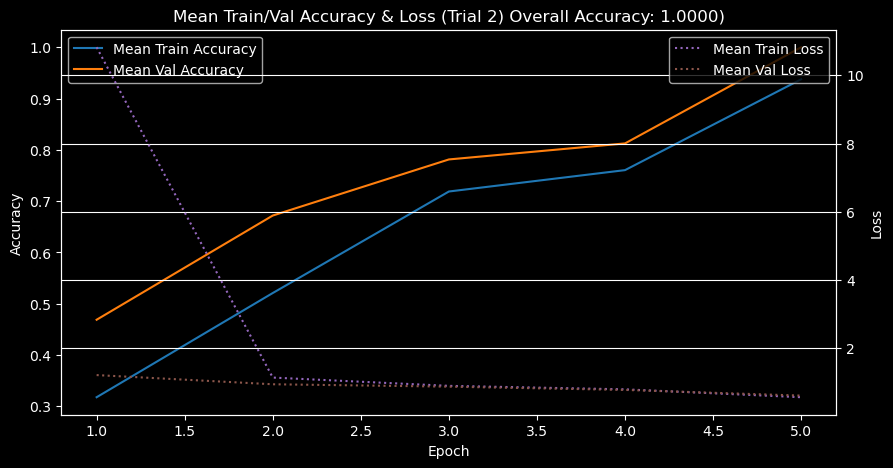

[I 2025-06-05 10:16:49,163] Trial 1 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'relu', 'learning_rate': 0.0014645262822775098, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 3.739826569487439e-05, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\

Trial 1 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9447664221127828


Trial: 4, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 4, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 16.


Trial: 4, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping triggered after 29 epochs (no val_loss improvement).


Trial: 4, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 13.


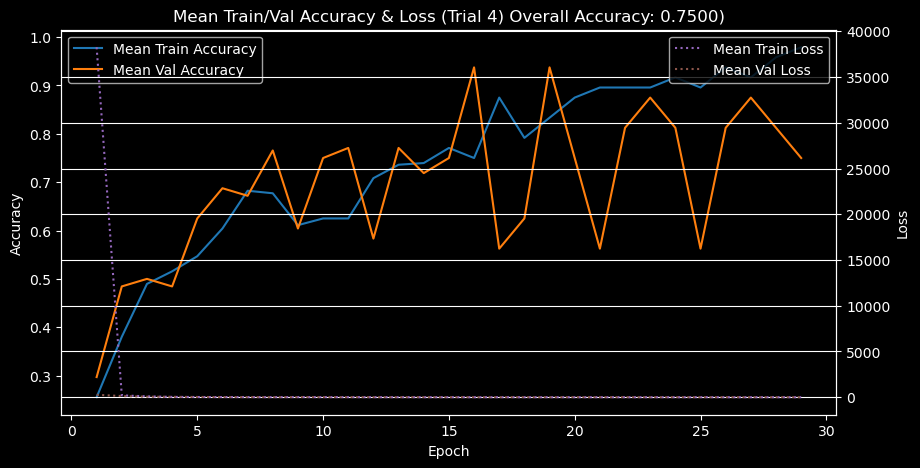

[I 2025-06-05 10:37:08,140] Trial 3 finished with value: 0.953125 and parameters: {'window_size': 8, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 64, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_rate': 0.0019137942785437542, 'batch_size': 4, 'dropout_rate': 0.1, 'optimizer': 'rmsprop', 'weight_decay': 1.0596922343956097e-06, 'label_smoothing': 0.15, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 3 - Best Avg Val Acc: 0.953125, Best Avg Val Loss: 64.22716392003574


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 5, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 5, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 5, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 5, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


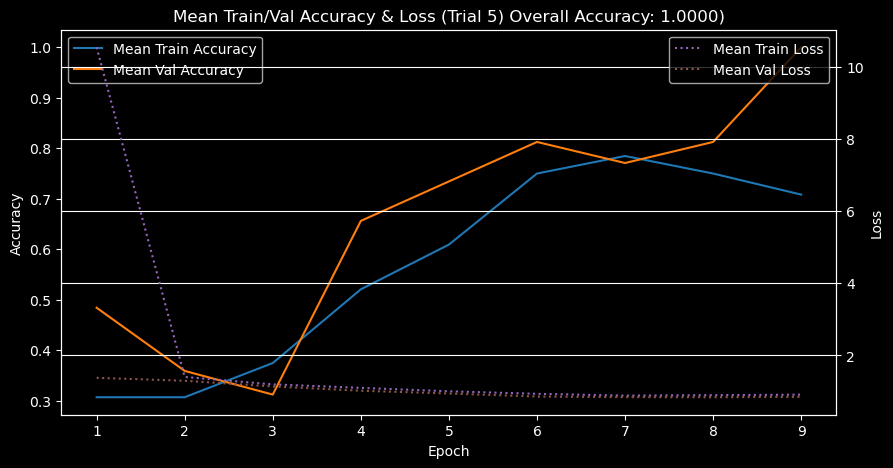

[I 2025-06-05 10:38:02,890] Trial 4 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0010018186130888653, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 5.76126725595844e-05, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\User

Trial 4 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.054322600364685


Trial: 7, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 7, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 7, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 7, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


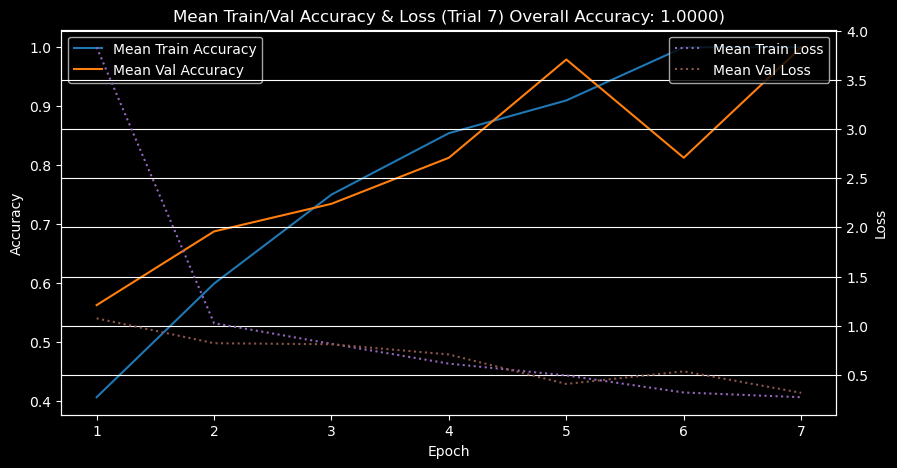

[I 2025-06-05 11:41:02,088] Trial 6 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0005333862503196541, 'batch_size': 2, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adam', 'weight_decay': 2.877048953249626e-07, 'label_smoothing': 0.05, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 6 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8157271329313517


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 8, Fold index: 1:   0%|          | 0/30 [00:01<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 8, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 8, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 8, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


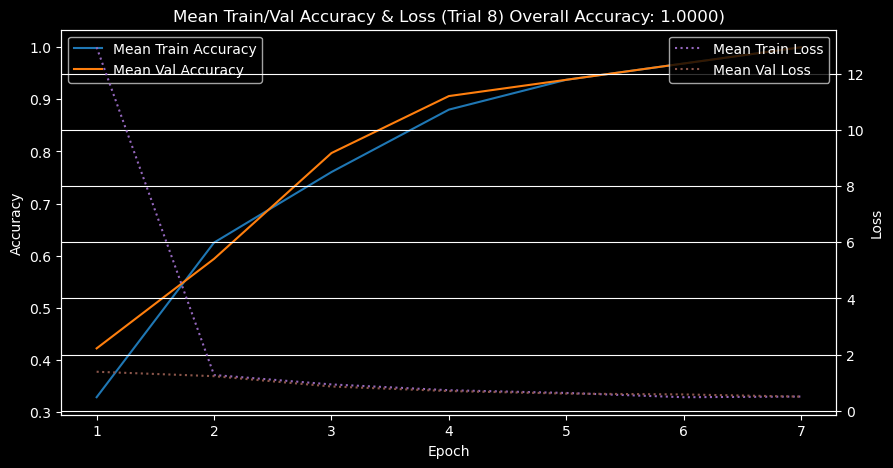

[I 2025-06-05 11:57:17,042] Trial 7 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 128, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0010234092827036034, 'batch_size': 2, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 2.797124751865795e-07, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 7 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8385586456528732


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 9, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 9, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 9, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 10.


Trial: 9, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


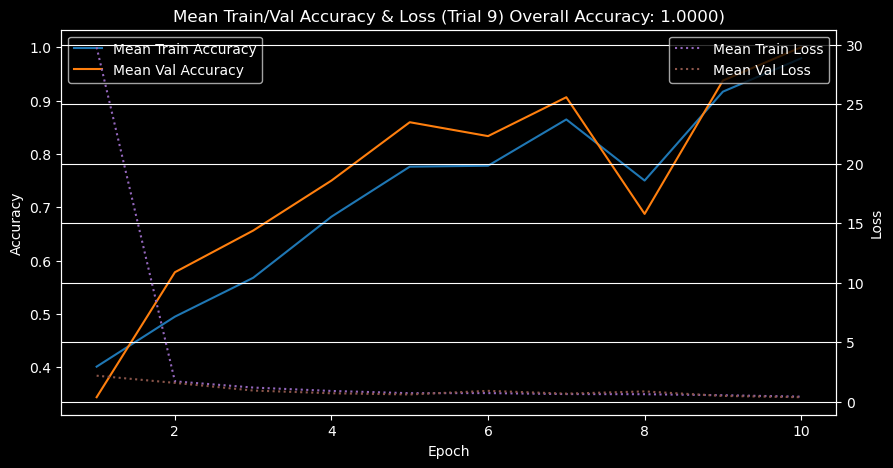

[I 2025-06-05 12:41:40,060] Trial 8 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 128, 'lstm2_cells': 64, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0008424067363463332, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 1.2891549462677047e-05, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 8 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8976682567348083


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 10, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 2.


Trial: 10, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 2.


Trial: 10, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 2.


Trial: 10, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


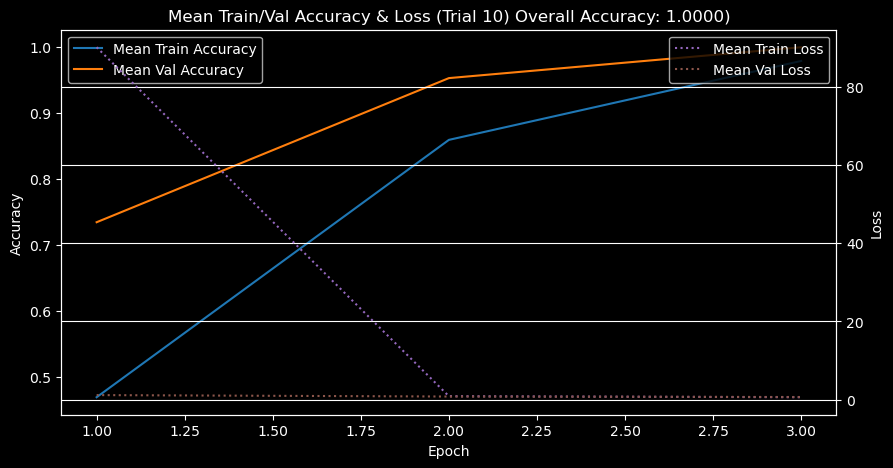

[I 2025-06-05 12:51:40,444] Trial 9 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 128, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'gelu', 'learning_rate': 0.0005801988416795073, 'batch_size': 2, 'dropout_rate': 0.1, 'optimizer': 'rmsprop', 'weight_decay': 4.861327789245292e-05, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 9 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9597459621727467


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 11, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 11, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 11, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 11, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


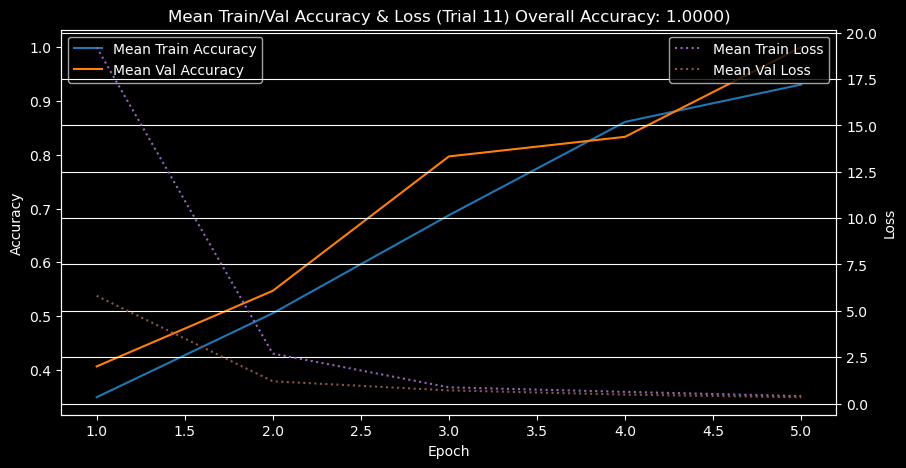

[I 2025-06-05 12:53:46,443] Trial 10 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.0015192773404877986, 'batch_size': 8, 'dropout_rate': 0.25, 'optimizer': 'adam', 'weight_decay': 4.15334253664829e-06, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 10 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 2.36099049448967


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 12, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 12, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 12, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 12, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 2.


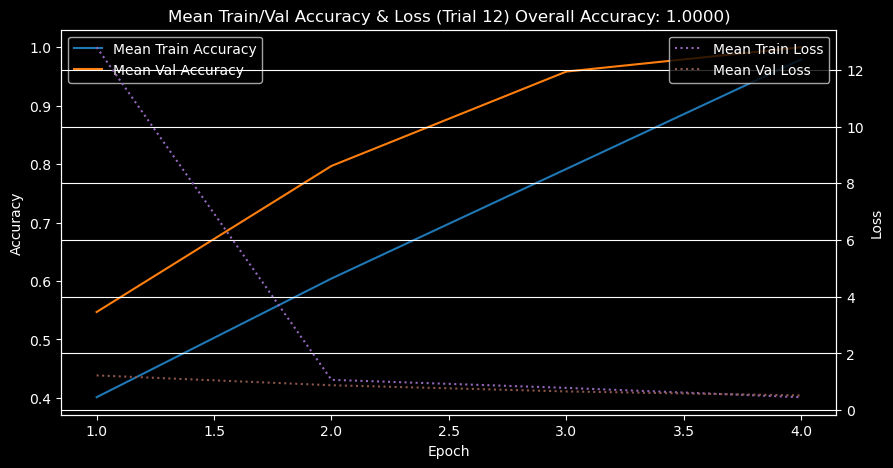

[I 2025-06-05 13:14:24,493] Trial 11 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_rate': 0.0014321332569924503, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 1.0258582009341025e-07, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 11 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.0367223992943764


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 13, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 13, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 13, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 13, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


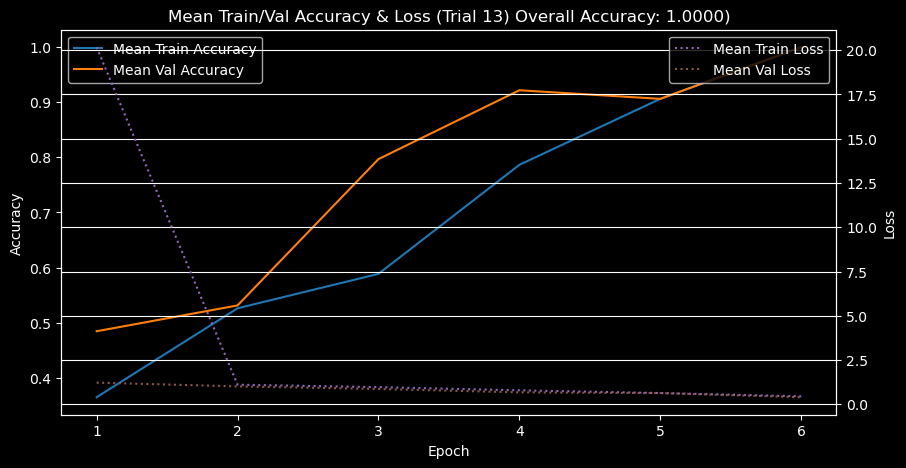

[I 2025-06-05 13:35:27,382] Trial 12 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0012646447605907745, 'batch_size': 8, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 3.415656492411408e-06, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 12 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9101237058639526


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 14, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 14, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 14, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 14, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


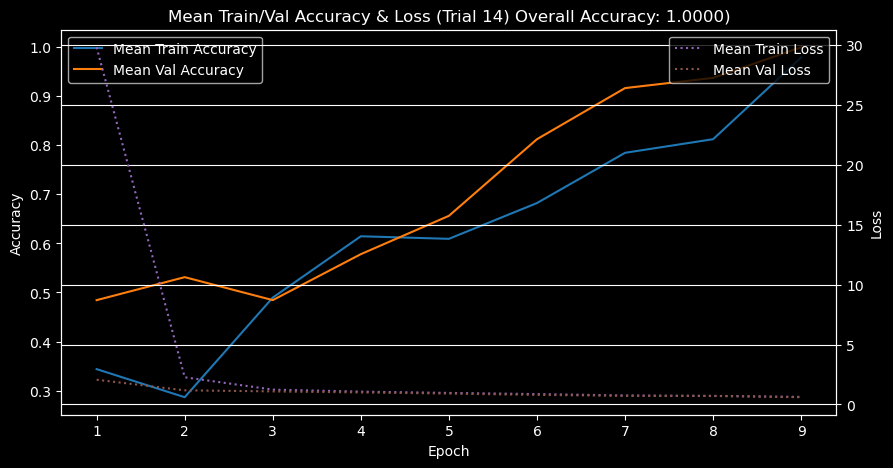

[I 2025-06-05 13:50:13,377] Trial 13 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_rate': 0.0018605832322789561, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'adam', 'weight_decay': 1.4350596377374949e-05, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 13 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.3793881790978568


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 15, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 2.


Trial: 15, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 15, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 21.


Trial: 15, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


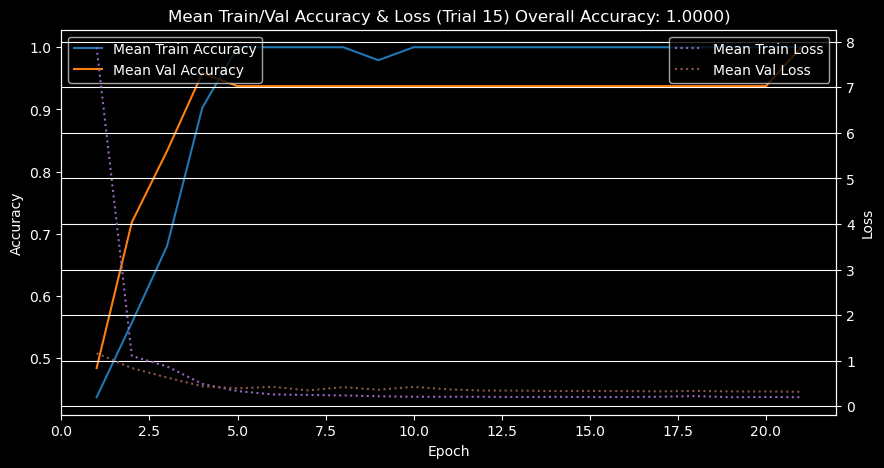

[I 2025-06-05 14:25:11,055] Trial 14 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'relu', 'learning_rate': 0.001303282259350932, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 1.3004355580838024e-06, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 14 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8264652891084552


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 16, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 16, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 16, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 16, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


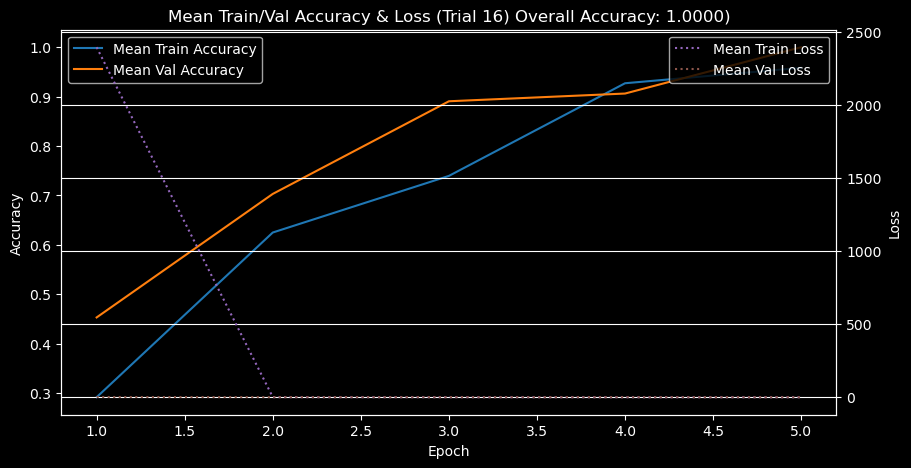

[I 2025-06-05 14:28:07,295] Trial 15 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.0011333563277927245, 'batch_size': 8, 'dropout_rate': 0.15000000000000002, 'optimizer': 'rmsprop', 'weight_decay': 1.755061857882058e-05, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 15 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.0148545503616333


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 17, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 17, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 17, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 17, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


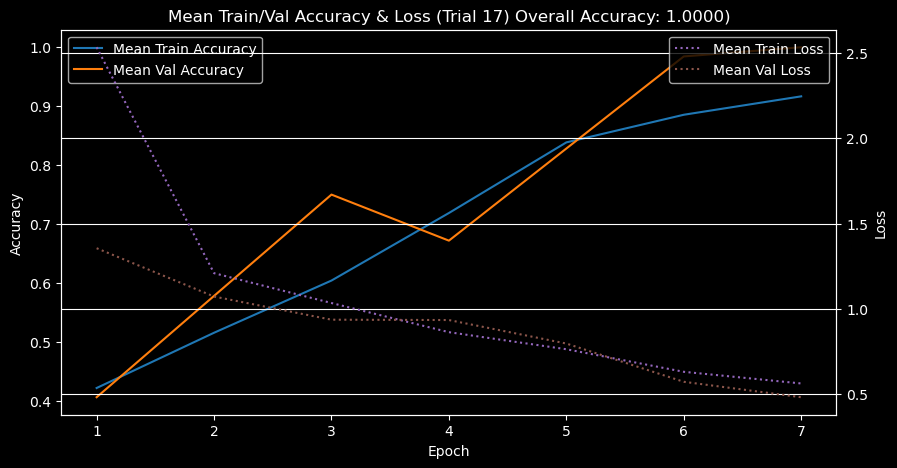

[I 2025-06-05 14:29:46,769] Trial 16 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0007792515080009043, 'batch_size': 8, 'dropout_rate': 0.25, 'optimizer': 'adam', 'weight_decay': 6.020945271794639e-06, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 16 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8595938576119286


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 18, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 18, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 18, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 18, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


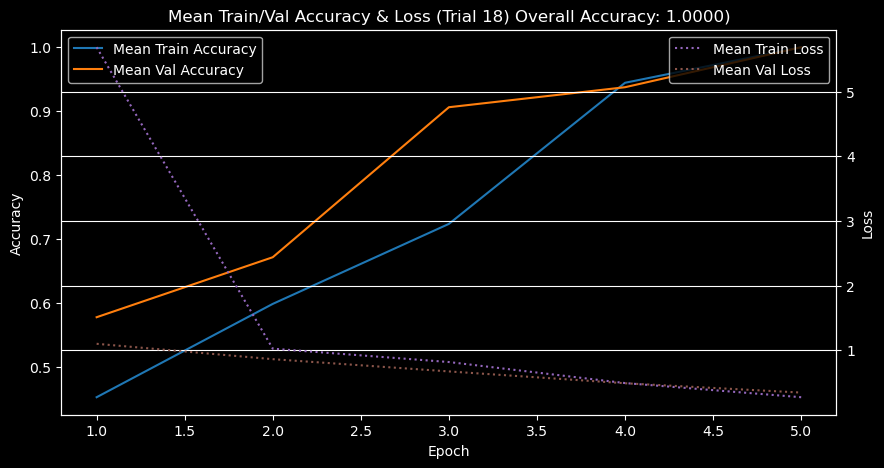

[I 2025-06-05 14:52:17,706] Trial 17 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 64, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_rate': 0.0006672894121098969, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 1.632843416900153e-06, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 17 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.7842811346054077


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 19, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Trial: 19, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 13.


Trial: 19, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 21.


Trial: 19, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 21.


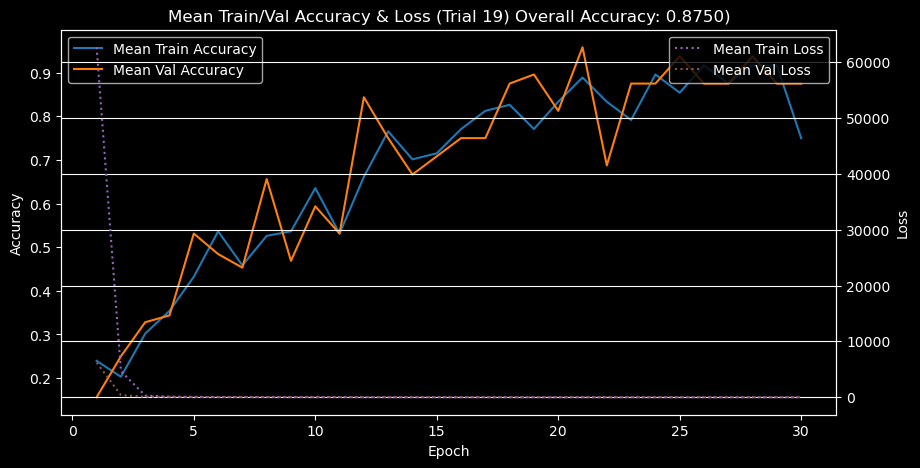

[I 2025-06-05 15:03:12,155] Trial 18 finished with value: 0.9375 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0015825065456145984, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'rmsprop', 'weight_decay': 1.052234778221293e-07, 'label_smoothing': 0.15, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 18 - Best Avg Val Acc: 0.9375, Best Avg Val Loss: 400.8817358925229


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 20, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 20, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 20, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 20, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


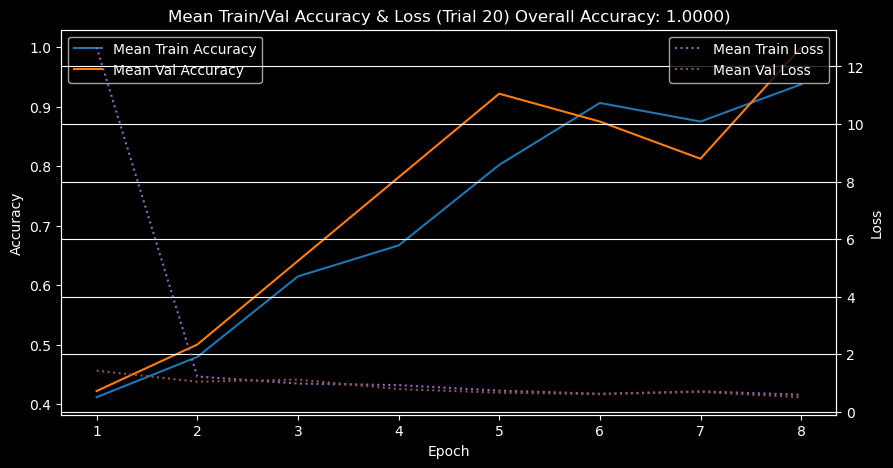

[I 2025-06-05 15:20:01,038] Trial 19 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_rate': 0.0011725069726447575, 'batch_size': 8, 'dropout_rate': 0.2, 'optimizer': 'adamw', 'weight_decay': 2.9911016925283056e-05, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 19 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8802630603313446


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 21, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 21, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 21, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 21, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


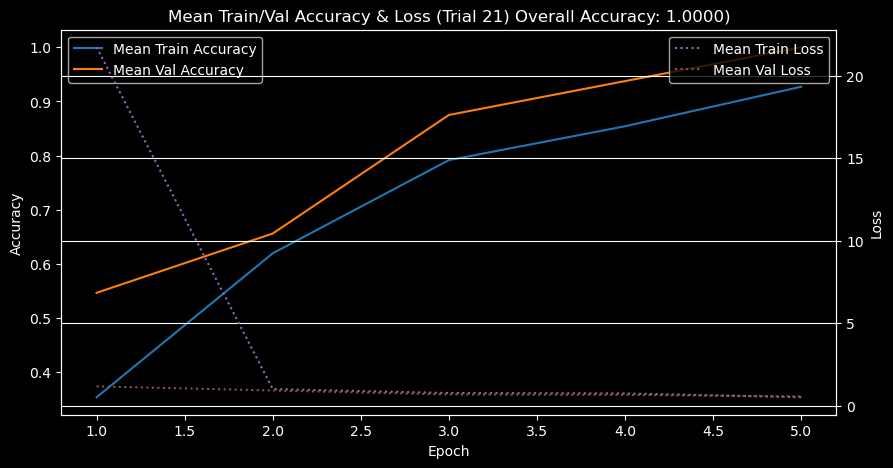

[I 2025-06-05 16:20:26,436] Trial 20 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 64, 'dense3_nodes': 128, 'dense3_activation': 'relu', 'learning_rate': 0.001667070175198065, 'batch_size': 4, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adam', 'weight_decay': 5.821328234788326e-07, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 20 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.7836783478657404


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 22, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 22, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 22, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 22, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


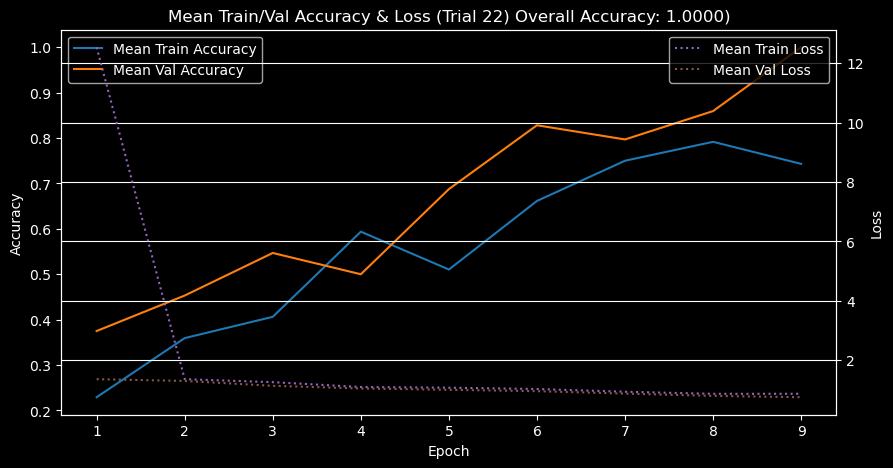

[I 2025-06-05 16:25:29,354] Trial 21 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0010026455962103386, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 8.964038054626957e-05, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 21 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.013261616230011


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 23, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 10.


Trial: 23, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 12.


Trial: 23, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 10.


Trial: 23, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


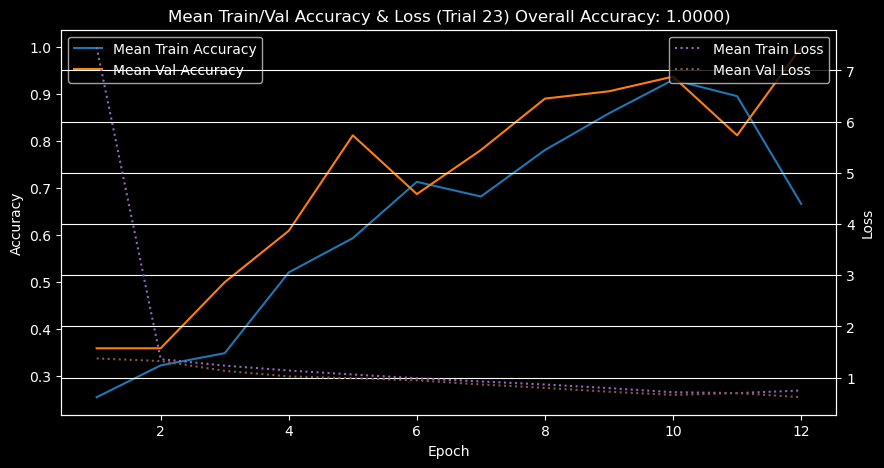

[I 2025-06-05 16:52:35,755] Trial 22 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0009743320917210323, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 4.7191100224663024e-05, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 22 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.0164569814999898


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 24, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 24, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 24, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 24, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 10.


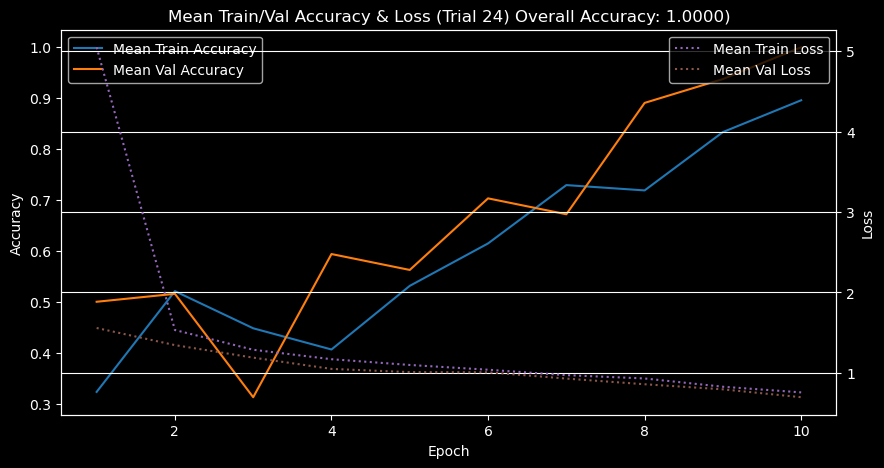

[I 2025-06-05 16:58:13,127] Trial 23 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0007205146978328719, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 8.531351530676487e-06, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 23 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.061447125673294


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 25, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 25, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 25, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 25, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


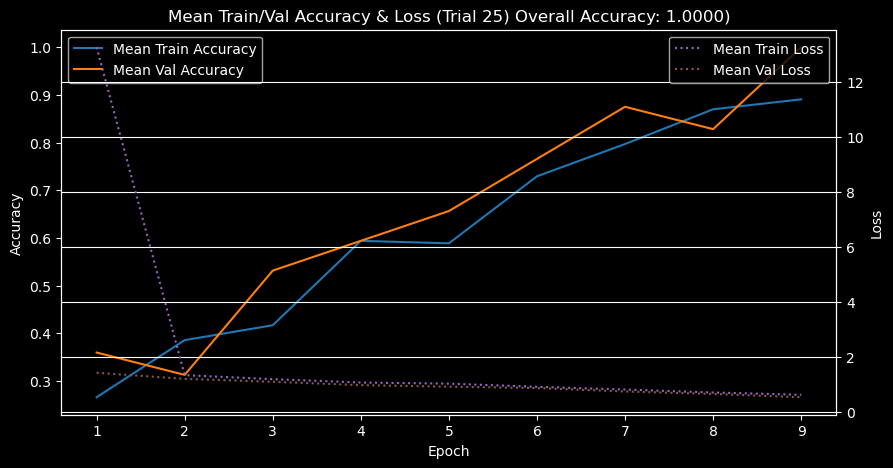

[I 2025-06-05 17:02:06,418] Trial 24 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 32, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.001360545024125788, 'batch_size': 16, 'dropout_rate': 0.2, 'optimizer': 'adamw', 'weight_decay': 3.96903135513924e-05, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 24 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9607180224524604


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 26, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 26, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 26, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 26, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


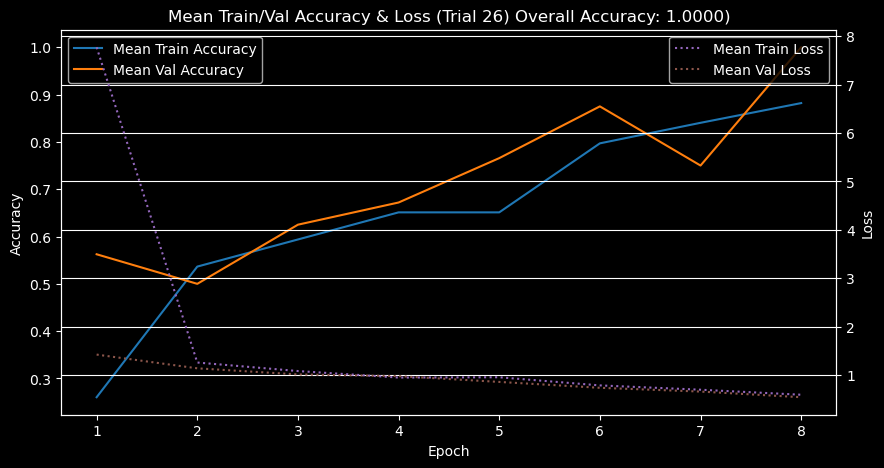

[I 2025-06-05 17:08:43,378] Trial 25 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0011533018984436051, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 2.452901293241596e-05, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 25 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8379784524440765


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 27, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 27, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 27, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 27, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


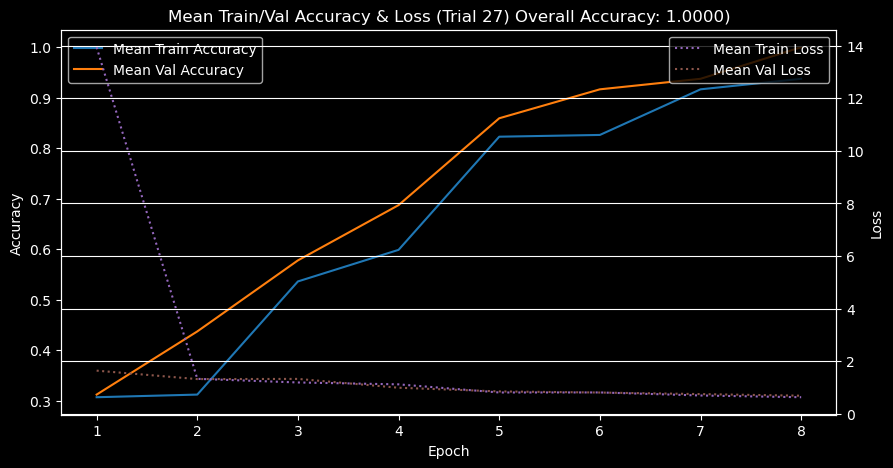

[I 2025-06-05 17:10:06,651] Trial 26 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.0009607732580011296, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 2.3692412279682445e-06, 'label_smoothing': 0.15, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 26 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.0656264151136081


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 28, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 28, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 28, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 12.


Trial: 28, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


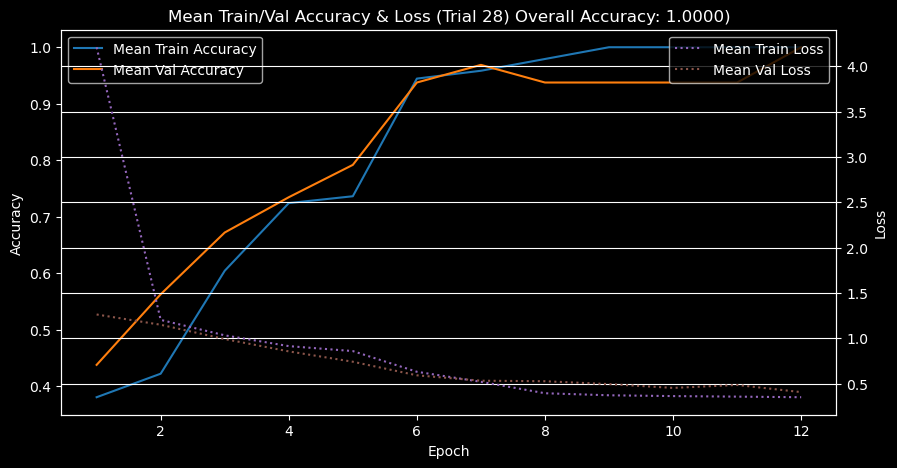

[I 2025-06-05 17:12:26,546] Trial 27 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0010967903699894534, 'batch_size': 8, 'dropout_rate': 0.25, 'optimizer': 'adam', 'weight_decay': 7.91644028362565e-06, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 27 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9187846481800079


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 29, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 29, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 29, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 29, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


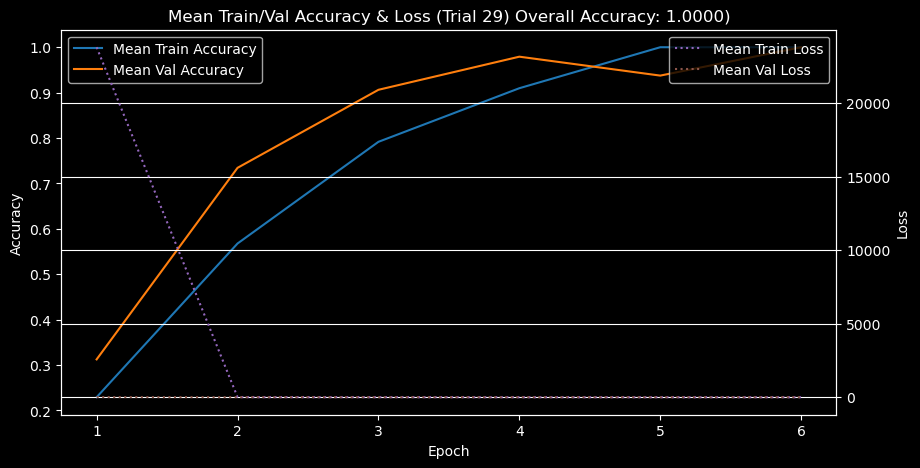

[I 2025-06-05 17:26:18,542] Trial 28 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 64, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0016688241436403036, 'batch_size': 8, 'dropout_rate': 0.25, 'optimizer': 'rmsprop', 'weight_decay': 9.320569016867254e-05, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\a

Trial 28 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.2858073165019352


Trial: 31, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 31, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 31, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 10.


Trial: 31, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


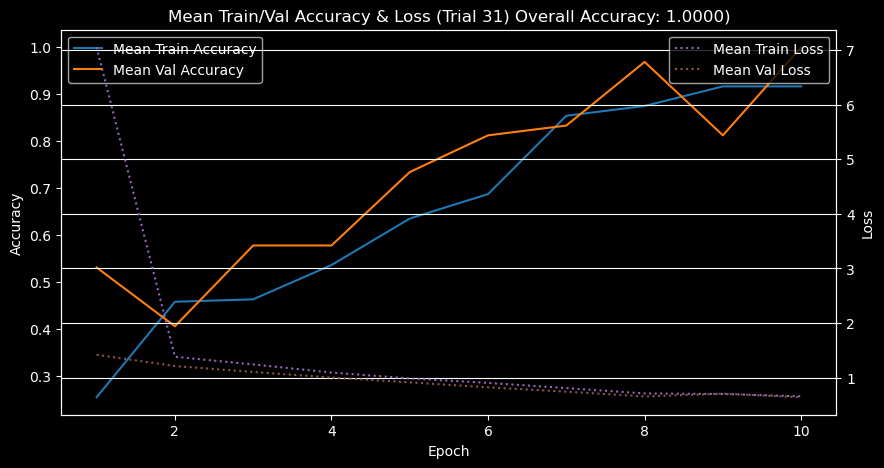

[I 2025-06-05 17:30:44,767] Trial 30 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 128, 'dense3_nodes': 128, 'dense3_activation': 'relu', 'learning_rate': 0.0012763720763460007, 'batch_size': 16, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adamw', 'weight_decay': 2.4028522204520217e-05, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 30 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.0416231552759807


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 32, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 32, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 32, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 32, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


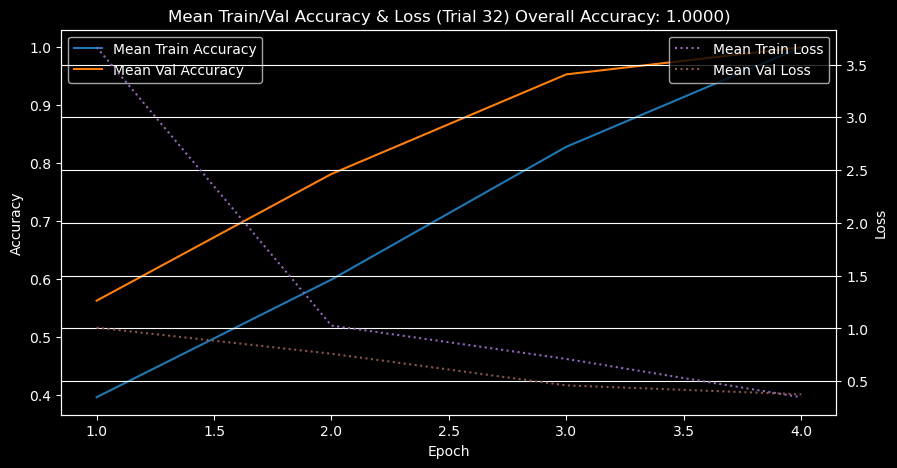

[I 2025-06-05 18:14:00,837] Trial 31 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0005407120854174896, 'batch_size': 2, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adam', 'weight_decay': 2.5020638554357787e-07, 'label_smoothing': 0.05, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 31 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8320711739361286


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 33, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 33, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 33, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 33, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


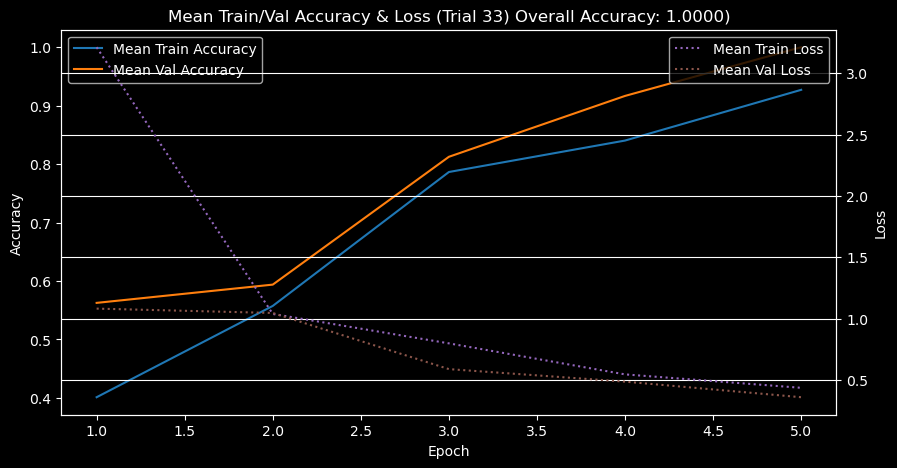

[I 2025-06-05 19:10:39,389] Trial 32 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.00043580867739376937, 'batch_size': 2, 'dropout_rate': 0.1, 'optimizer': 'adam', 'weight_decay': 2.403571322842157e-07, 'label_smoothing': 0.05, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 32 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.7403888969371716


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 34, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 34, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 34, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 34, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


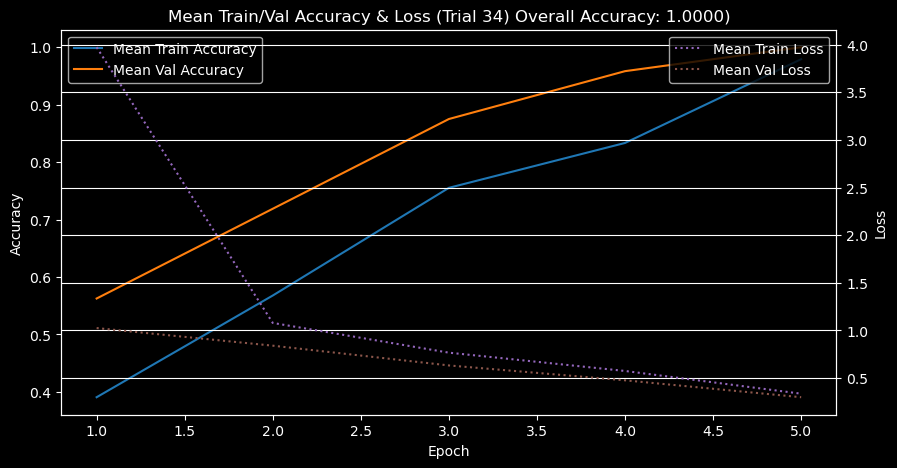

[I 2025-06-05 20:04:29,904] Trial 33 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0006229846107522842, 'batch_size': 2, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adam', 'weight_decay': 3.968532175746188e-07, 'label_smoothing': 0.05, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 33 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.7278301347978413


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 35, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 35, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 35, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 12.


Trial: 35, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


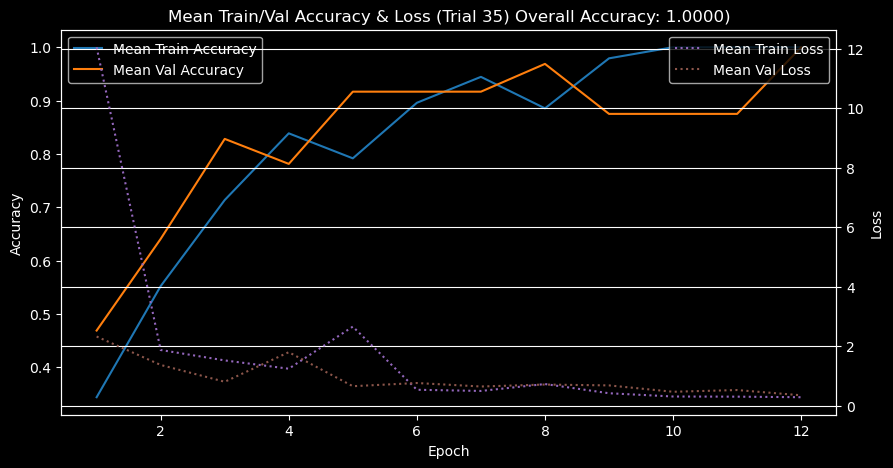

[I 2025-06-05 21:32:41,608] Trial 34 finished with value: 0.984375 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0005115523492826598, 'batch_size': 2, 'dropout_rate': 0.1, 'optimizer': 'adam', 'weight_decay': 8.811491311415017e-07, 'label_smoothing': 0.05, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 34 - Best Avg Val Acc: 0.984375, Best Avg Val Loss: 1.5236377923283726


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 36, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 36, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 8.


Trial: 36, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 36, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


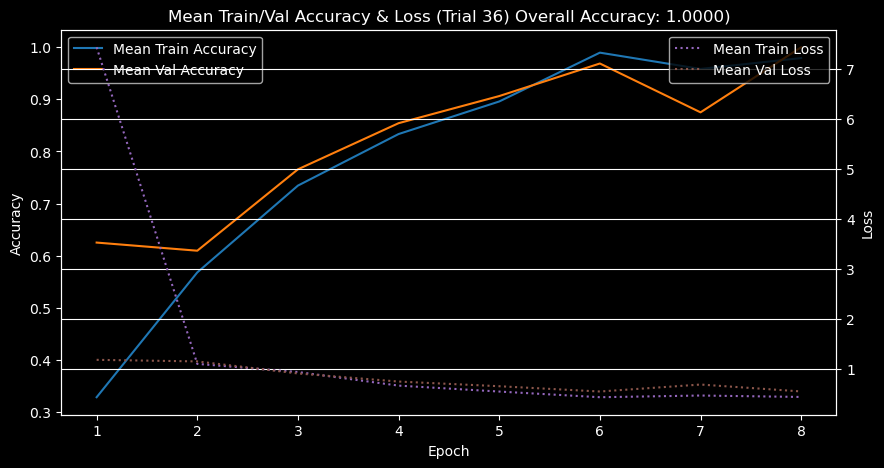

[I 2025-06-05 21:55:46,615] Trial 35 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0008587347856910497, 'batch_size': 4, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adam', 'weight_decay': 1.6403631291634263e-07, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 35 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9257549891869227


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 37, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 37, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 37, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 37, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


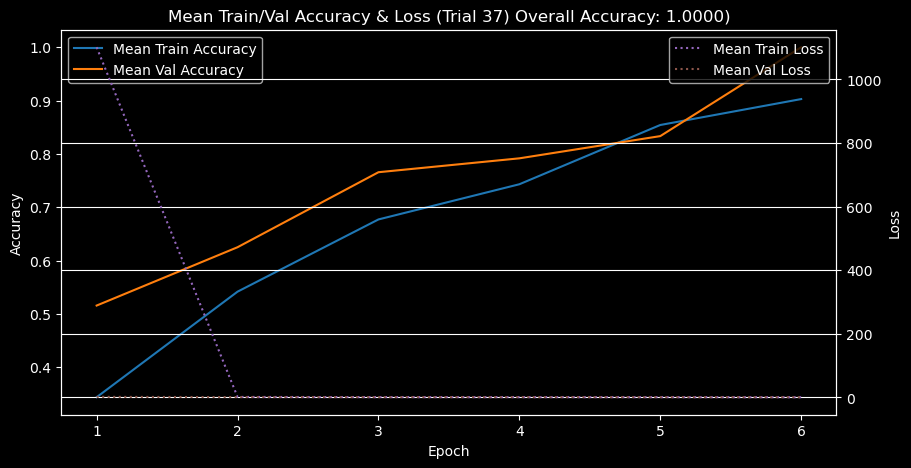

[I 2025-06-05 22:30:24,097] Trial 36 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 64, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.000913618784181137, 'batch_size': 2, 'dropout_rate': 0.15000000000000002, 'optimizer': 'rmsprop', 'weight_decay': 5.3563203745538346e-05, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 36 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8348513034482797


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 38, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 38, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 38, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 38, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


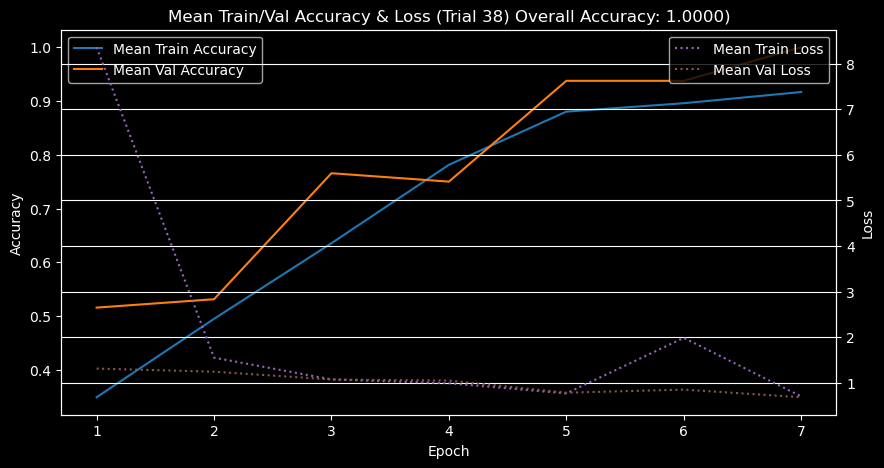

[I 2025-06-05 22:41:48,654] Trial 37 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.00077771453428361, 'batch_size': 4, 'dropout_rate': 0.1, 'optimizer': 'adam', 'weight_decay': 3.803672313246471e-07, 'label_smoothing': 0.15, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 37 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.1155184164643288


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 39, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 39, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 39, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 39, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


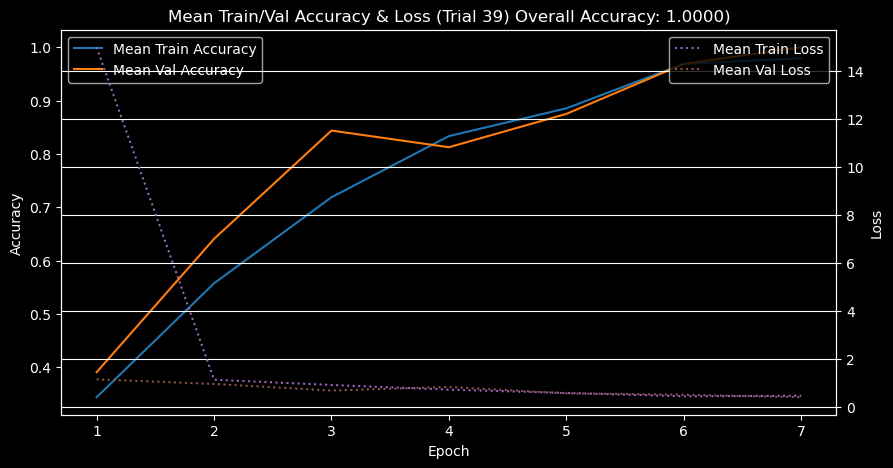

[I 2025-06-05 22:46:39,891] Trial 38 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 128, 'dense3_nodes': 128, 'dense3_activation': 'relu', 'learning_rate': 0.0019262896987545385, 'batch_size': 8, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 8.704973663177617e-07, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 38 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.9405728628238043


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 40, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 40, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 40, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 40, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


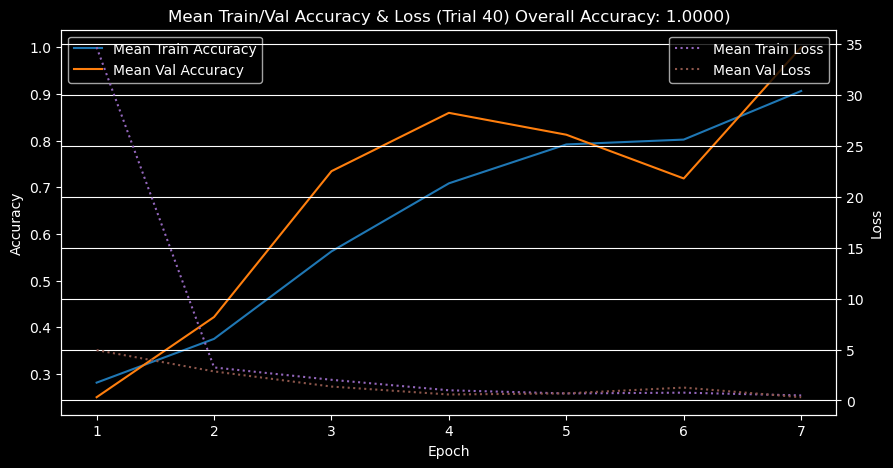

[I 2025-06-06 00:04:38,189] Trial 39 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.0010338354983142077, 'batch_size': 2, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 2.0966292794817512e-06, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 39 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.4405846279114485


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 41, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 41, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 3.


Trial: 41, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 41, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 2.


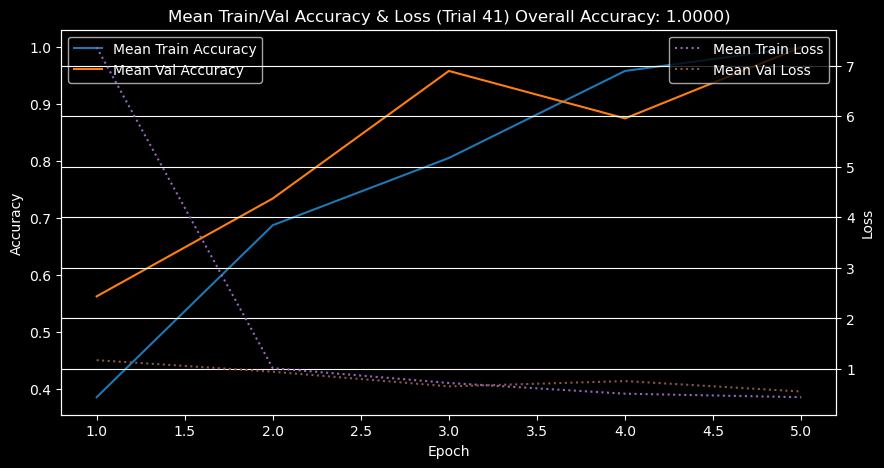

[I 2025-06-06 00:12:41,449] Trial 40 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 32, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0014186363677200333, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 6.25450847703402e-05, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\a

Trial 40 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.0361428782343864


Trial: 42, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 42, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 42, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 42, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


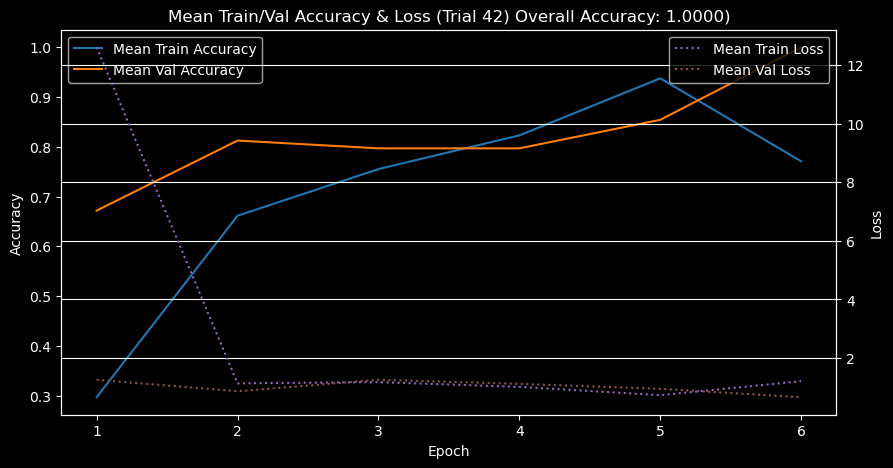

[I 2025-06-06 00:32:37,922] Trial 41 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 128, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.001055444669374596, 'batch_size': 2, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 1.9023080983198882e-07, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 41 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.4053830113261938


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 43, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 43, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 43, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 43, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


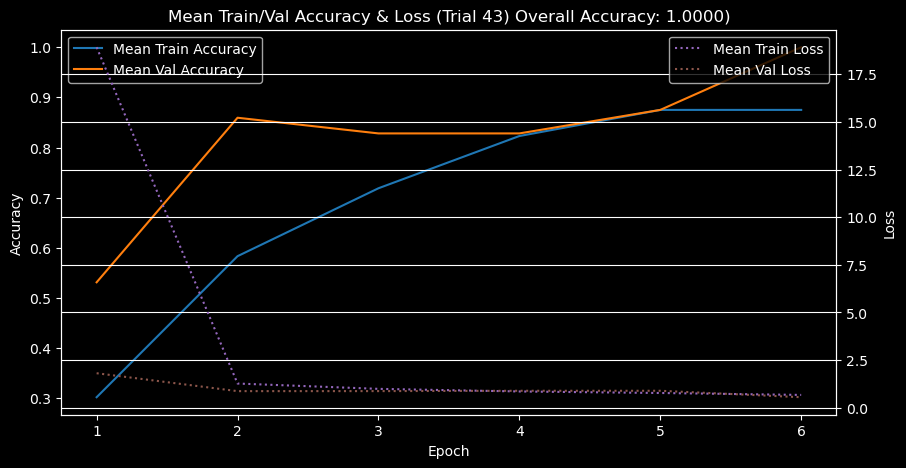

[I 2025-06-06 00:54:02,860] Trial 42 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 128, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0011886183958171176, 'batch_size': 2, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 2.844339935218389e-07, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 42 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8721562530845404


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 44, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 44, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 44, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 44, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


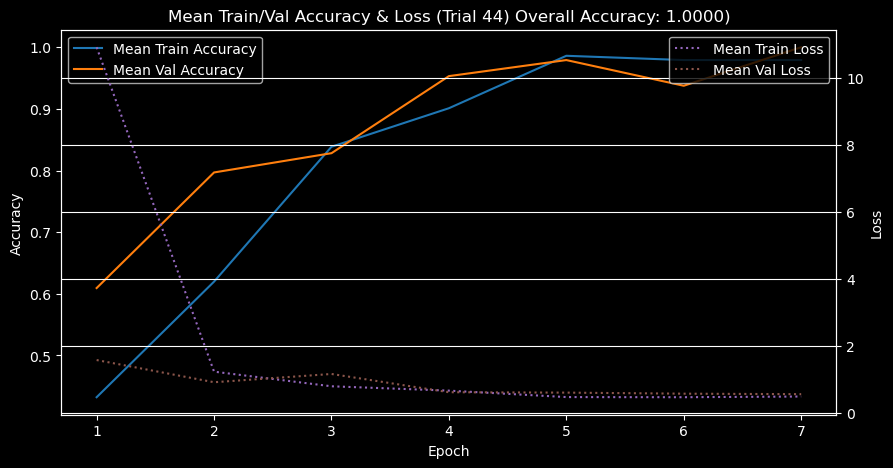

[I 2025-06-06 01:15:23,399] Trial 43 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 128, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0008013283687471268, 'batch_size': 2, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 1.5073488872460383e-07, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 43 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8947438545525074


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 45, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 45, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 45, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 45, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


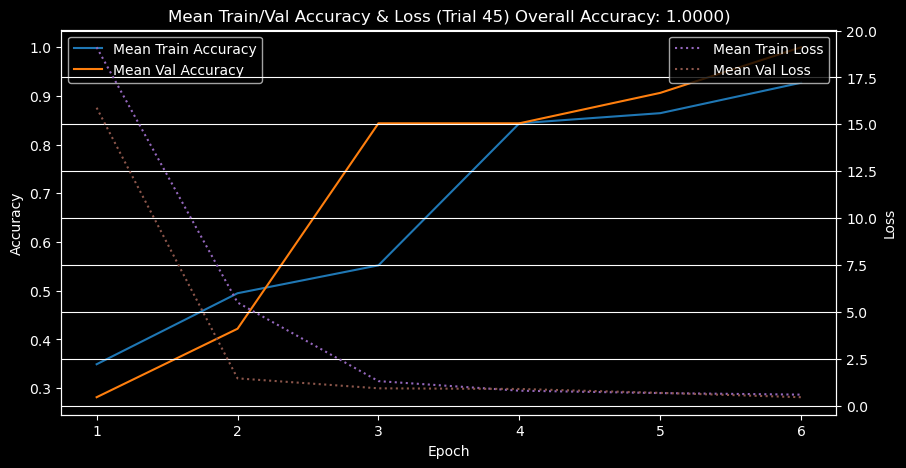

[I 2025-06-06 01:28:16,063] Trial 44 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0009060223923228344, 'batch_size': 8, 'dropout_rate': 0.25, 'optimizer': 'adam', 'weight_decay': 3.440433115465626e-07, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 44 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 3.329196773469448


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 46, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 20.


Trial: 46, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 46, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Trial: 46, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


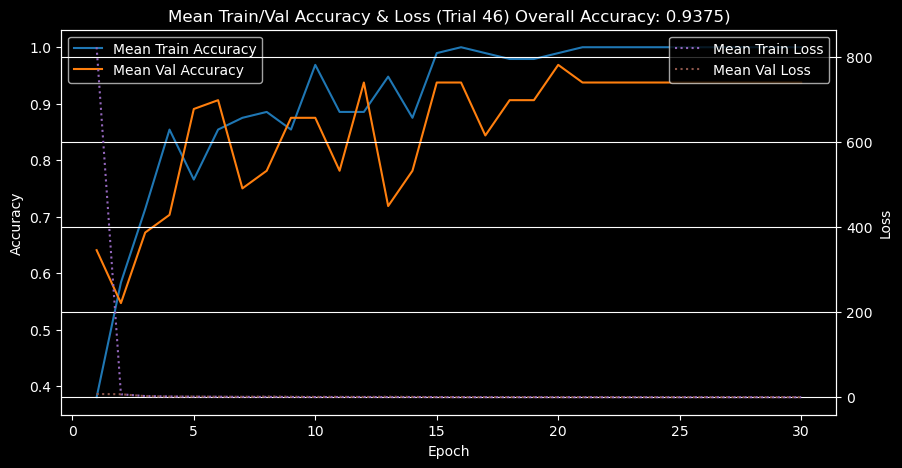

[I 2025-06-06 02:09:58,058] Trial 45 finished with value: 0.984375 and parameters: {'window_size': 16, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0007365070776498703, 'batch_size': 2, 'dropout_rate': 0.25, 'optimizer': 'rmsprop', 'weight_decay': 5.161545844425005e-07, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 45 - Best Avg Val Acc: 0.984375, Best Avg Val Loss: 1.9836490236222744


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 47, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 47, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 47, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Trial: 47, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


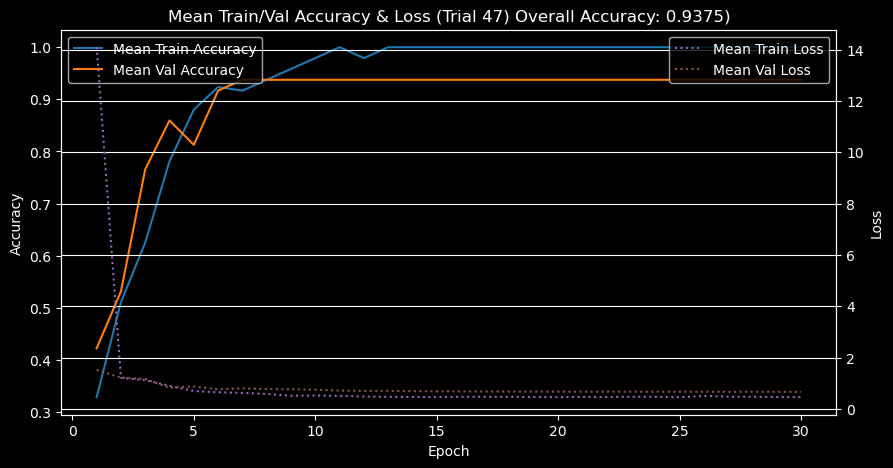

[I 2025-06-06 02:53:42,569] Trial 46 finished with value: 0.984375 and parameters: {'window_size': 18, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 64, 'lstm2_cells': 64, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.001459078048697686, 'batch_size': 4, 'dropout_rate': 0.2, 'optimizer': 'adamw', 'weight_decay': 4.284507241956612e-06, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 46 - Best Avg Val Acc: 0.984375, Best Avg Val Loss: 0.9996508049468199


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 48, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 48, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 48, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


Trial: 48, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 4.


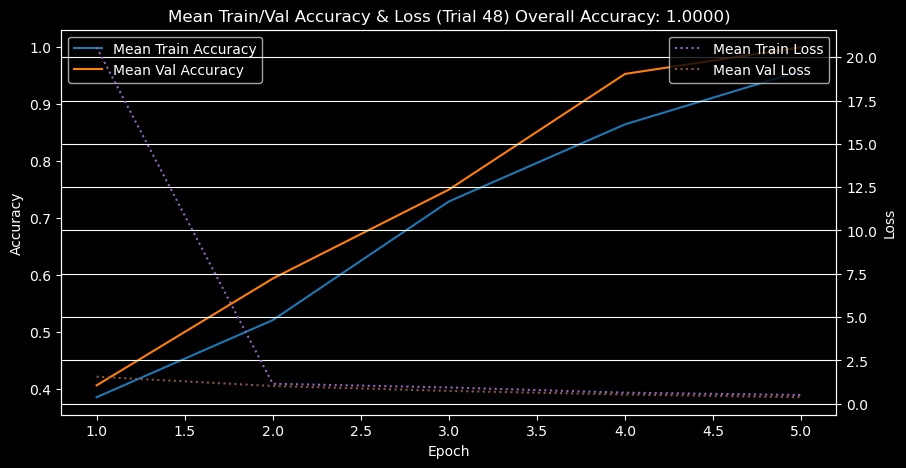

[I 2025-06-06 03:09:25,806] Trial 47 finished with value: 1.0 and parameters: {'window_size': 16, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 128, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.001757902372004834, 'batch_size': 8, 'dropout_rate': 0.25, 'optimizer': 'adam', 'weight_decay': 7.174509372024763e-07, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 47 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8068888708949089


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 49, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 49, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 6.


Trial: 49, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


Trial: 49, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


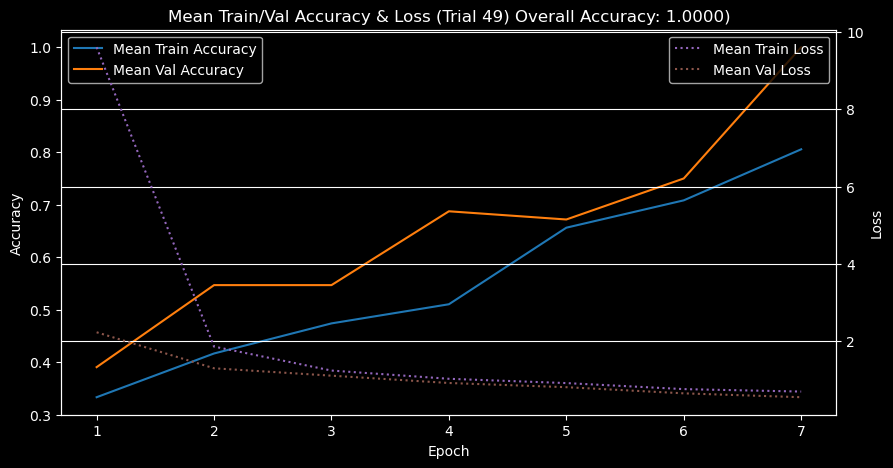

[I 2025-06-06 03:12:04,103] Trial 48 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_rate': 0.001231013980817407, 'batch_size': 16, 'dropout_rate': 0.2, 'optimizer': 'adam', 'weight_decay': 1.2027711817223799e-06, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 48 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.2566927671432495


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 50, Fold index: 1:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 50, Fold index: 2:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 5.


Trial: 50, Fold index: 3:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 9.


Trial: 50, Fold index: 4:   0%|          | 0/30 [00:00<?, ?epoch/s]

Early stopping: Validation accuracy reached 1.0 at epoch 7.


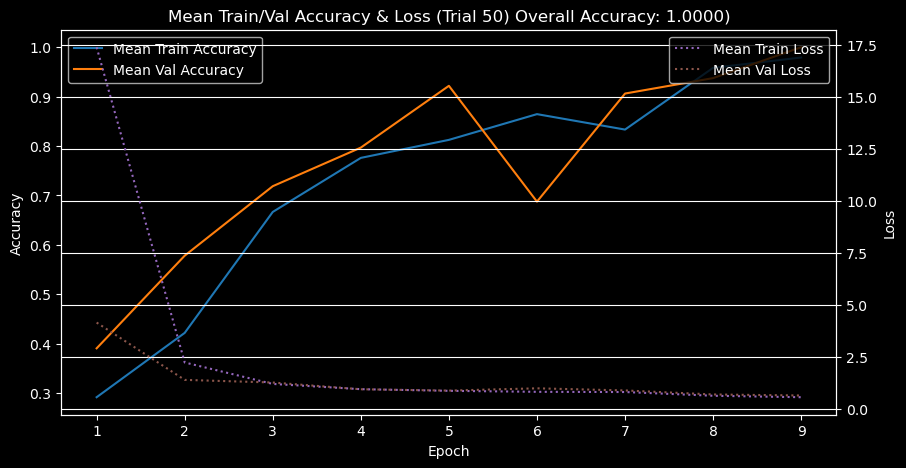

[I 2025-06-06 04:57:14,186] Trial 49 finished with value: 1.0 and parameters: {'window_size': 18, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'relu', 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 128, 'dense3_activation': 'relu', 'learning_rate': 0.0010734514596285214, 'batch_size': 2, 'dropout_rate': 0.25, 'optimizer': 'adamw', 'weight_decay': 1.101925032924607e-07, 'label_smoothing': 0.15, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 49 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 1.6008569917508535


In [10]:
import optuna
import json

number_of_trials = 50 # Number of trials for Optuna
number_of_folds = 4 # 2 # Number of folds for cross-validation
# Split on task type or patient id 
property_to_split_on = "task_type_cat" # "patient_id"  # Property to split on for cross-validation

# Prepare a global DataFrame for metrics
all_metrics_df = utils.create_metrics_df()


# Define a wrapper so Optuna only gets the accuracy
def optuna_objective(trial):
    global all_metrics_df

    plot_path = f"{output_dir}/{which_dataset}/optuna_plots_{model_name}_trial_{trial.number}_timestamp_{timestamp}.png"

    best_avg_val_acc, best_avg_val_loss, updated_metrics_df = utils.objective(
        trial, all_metrics_df, train_data, train_df, device,
        n_splits=number_of_folds, best_model_path=model_pth_path, plot_path=plot_path,
        property_to_split_on=property_to_split_on
    )
    all_metrics_df = updated_metrics_df  # update global after each trial
    print(f"Trial {trial.number} - Best Avg Val Acc: {best_avg_val_acc}, Best Avg Val Loss: {best_avg_val_loss}")
    return best_avg_val_acc  # maximize accuracy

# Run Optuna and save best model after all trials
study = optuna.create_study(direction="maximize")  # or "maximize" based on your objective
study.optimize(optuna_objective, n_trials=number_of_trials)

### Training stage #2 train on full train dataset with best paramters chosen

Full Training:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 44 epochs (no train_loss improvement).
Total Train Accuracy: 0.9563


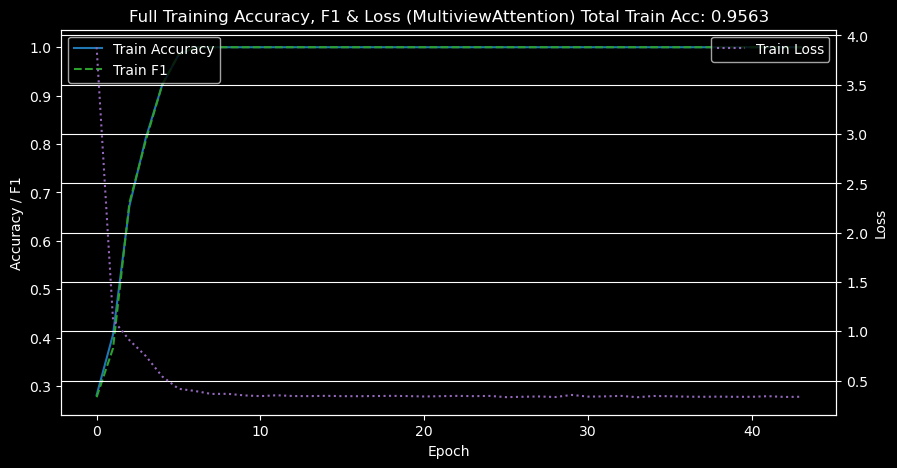

In [11]:
import importlib
importlib.reload(utils)

path = f"{output_dir}/{which_dataset}/full_training_metrics_{model_name}_{timestamp}.png"
best_model, best_params, _, train_accs, train_f1s, train_losses = utils.train_full_model(
    study,
    train_data,
    train_df,
    device,
    epochs=50,
    path=path
)

### Training stage #3 saving the final model

In [12]:
# Create the model with the best hyperparameters
torch.save(best_model.state_dict(), model_pth_path)
print(f"Best model saved to {model_pth_path}")

# Save the best hyperparameters to a JSON file
with open(model_json_path, "w") as json_file:
    json.dump(best_params, json_file, indent=4)
print(f"Best hyperparameters saved to {model_json_path}")

Best model saved to ./Models/cross/best_model_MultiviewAttention_cross_20250605_100311.pth
Best hyperparameters saved to ./Models/cross/best_model_MultiviewAttention_cross_20250605_100311.json


### Evaluate model and save logs

In [13]:
import importlib
importlib.reload(utils)

test_metrics, df_test_result, all_metrics_df = utils.evaluate_and_log_testset(
    study,
    best_model,
    best_params,
    test_data,
    test_df,
    device,
    all_metrics_df,
    model_csv_path,
    output_dir,
    which_dataset,
    model_name,
    timestamp
)

Test metrics: {'overall_accuracy': 0.7291666666666666, 'overall_F1': 0.7301851851851853, 'overall_recall': 0.7291666666666667, 'overall_precision': 0.750801282051282, 'resting_accuracy': 1.0, 'resting_F1': 1.0, 'resting_recall': 1.0, 'resting_precision': 1.0, 'math_accuracy': 0.8333333333333334, 'math_F1': 0.45454545454545453, 'math_recall': 0.4166666666666667, 'math_precision': 0.5, 'memory_accuracy': 0.5, 'memory_F1': 0.2222222222222222, 'memory_recall': 0.16666666666666666, 'memory_precision': 0.3333333333333333, 'motor_accuracy': 0.5833333333333334, 'motor_F1': 0.3684210526315789, 'motor_recall': 0.2916666666666667, 'motor_precision': 0.5} 
Best trial ID: 1 

All metrics saved to ./Output/cross/best_model_MultiviewAttention_cross_20250605_100311.csv
Best hyperparameters: {'window_size': 8, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_act

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\utils.py:1168: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.05, 1.0))


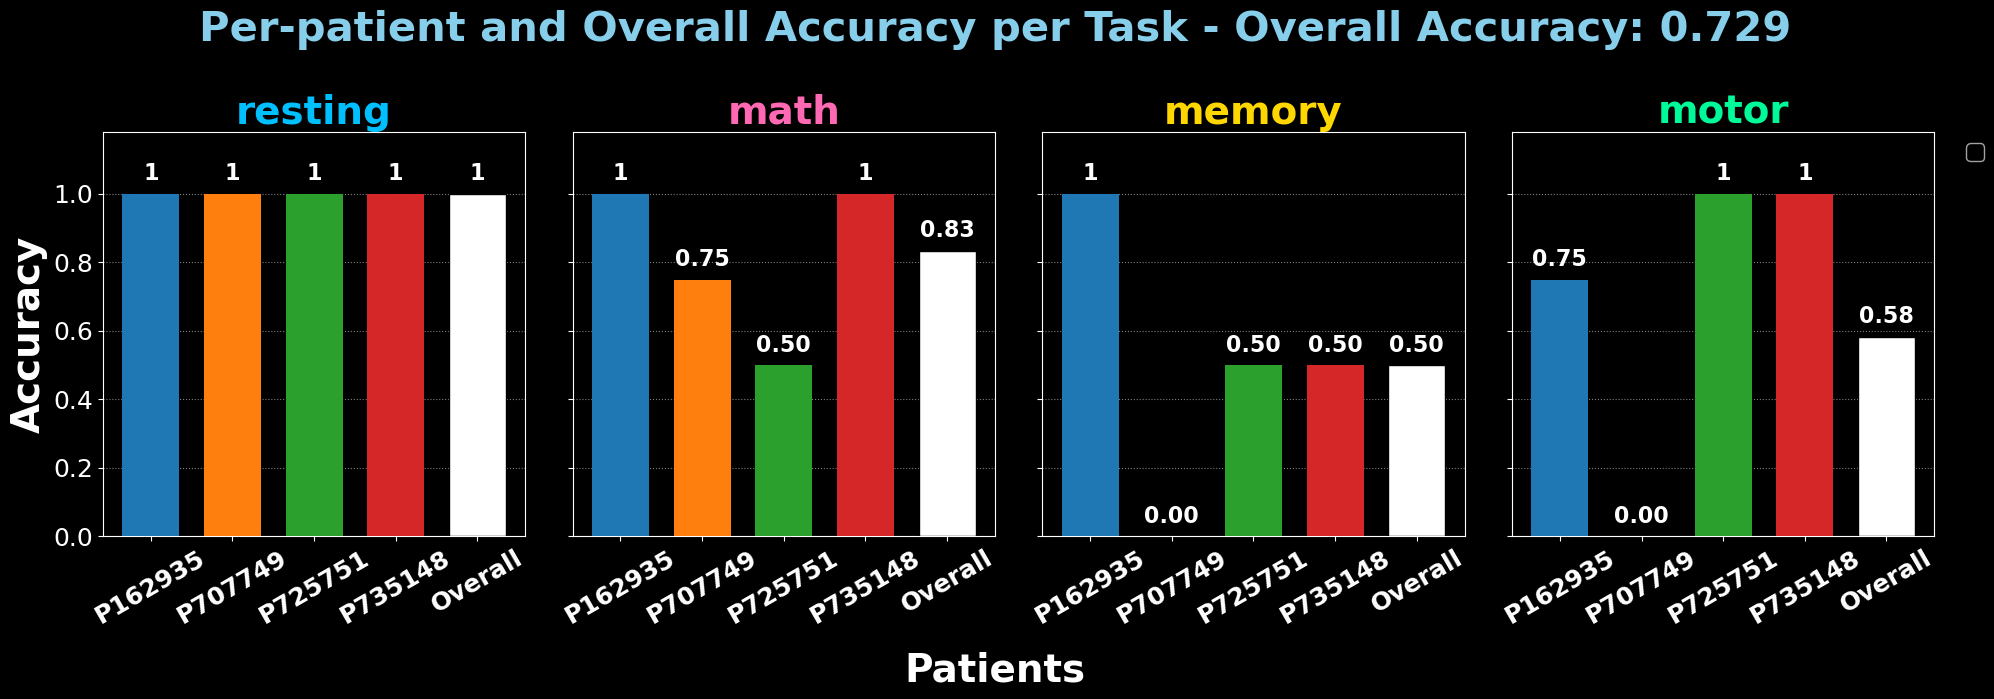

In [14]:
import importlib
importlib.reload(utils)

fig, axs, path, per_patient_acc, overall_acc_per_task = utils.plot_per_patient_accuracy_bars(
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

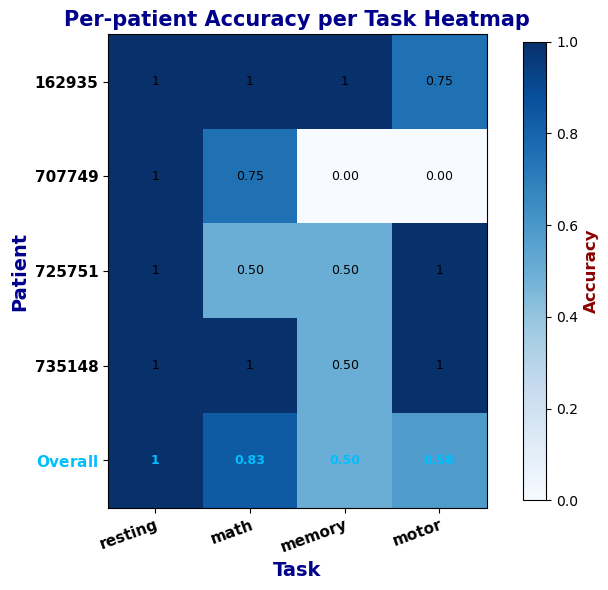

(<Figure size 1000x600 with 2 Axes>,
 <Axes: title={'center': 'Per-patient Accuracy per Task Heatmap'}, xlabel='Task', ylabel='Patient'>,
 './Output/cross/per_patient_accuracy_heatmap_MultiviewAttention_cross_20250605_100311.png')

In [15]:
import importlib
importlib.reload(utils)

utils.plot_per_patient_accuracy_heatmap(
    per_patient_acc,
    overall_acc_per_task,
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

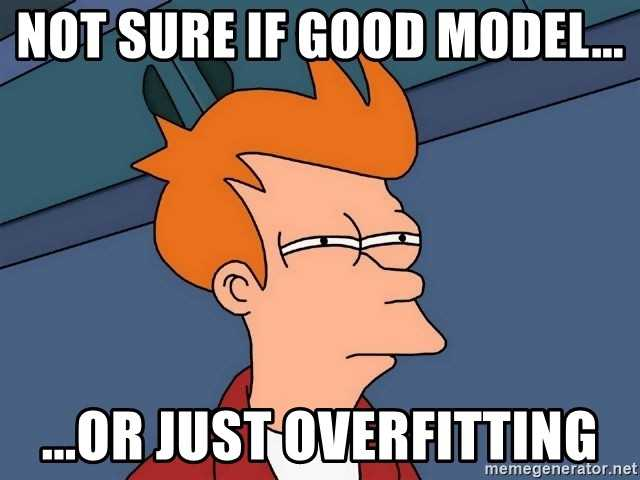

In [16]:
from IPython.display import Image, display

display(Image(filename="overfitunsurefry.webp"))

### Display first few lines from logs

In [17]:
from IPython.display import display, HTML

# Show the first 10 rows of the DataFrame in a scrollable box
display(HTML(all_metrics_df.head(10).to_html(max_rows=10, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

,trial_id,epoch,train_overall_accuracy,train_overall_F1,train_overall_recall,train_overall_precision,train_resting_accuracy,train_resting_F1,train_resting_recall,train_resting_precision,train_math_accuracy,train_math_F1,train_math_recall,train_math_precision,train_memory_accuracy,train_memory_F1,train_memory_recall,train_memory_precision,train_motor_accuracy,train_motor_F1,train_motor_recall,train_motor_precision,val_overall_accuracy,val_overall_F1,val_overall_recall,val_overall_precision,val_resting_accuracy,val_resting_F1,val_resting_recall,val_resting_precision,val_math_accuracy,val_math_F1,val_math_recall,val_math_precision,val_memory_accuracy,val_memory_F1,val_memory_recall,val_memory_precision,val_motor_accuracy,val_motor_F1,val_motor_recall,val_motor_precision,test_overall_accuracy,test_overall_F1,test_overall_recall,test_overall_precision,test_resting_accuracy,test_resting_F1,test_resting_recall,test_resting_precision,test_math_accuracy,test_math_F1,test_math_recall,test_math_precision,test_memory_accuracy,test_memory_F1,test_memory_recall,test_memory_precision,test_motor_accuracy,test_motor_F1,test_motor_recall,test_motor_precision,window_size,conv1_filters,conv2_filters,conv3_filters,conv1_kernel_shape,conv2_kernel_shape,conv3_kernel_shape,padding1,padding2,padding3,conv1_activation,conv2_activation,conv3_activation,dense_nodes,dense_activation,depth,lstm1_cells,lstm2_cells,dense3_nodes,dense3_activation,number_classes,number_channels,mesh_rows,mesh_columns,split_size,learning_rate,batch_size,dropout_rate,optimizer,weight_decay,label_smoothing,number_of_heads,fold_index,train_loss,val_loss
0,1,1,0.250000,0.204891,0.250000,0.183932,0.000000,0.000000,0.000000,0.000000,0.416667,0.196078,0.138889,0.333333,0.500000,0.222222,0.166667,0.333333,0.083333,0.038462,0.020833,0.250000,0.2500,0.100000,0.2500,0.062500,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,1.00,1.000000,1.000,1.0,0.00,0.0,0.000,0.0,0.729167,0.730185,0.729167,0.750801,1.0,1.0,1.0,1.0,0.833333,0.454545,0.416667,0.5,0.5,0.222222,0.166667,0.333333,0.583333,0.368421,0.291667,0.5,8,128,256,128,"(5, 5)","(3, 3)","(3, 3)",2,2,1,gelu,leaky_relu,relu,256,relu,1,128,32,64,gelu,4,248,8,31,636,0.0011,8,0.25,adam,3.631207e-07,0.1,2,1.0,3.933644,1.334137
1,1,2,0.375000,0.295777,0.375000,0.408333,0.416667,0.294118,0.208333,0.500000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.083333,0.076923,0.041667,0.500000,0.6250,0.559524,0.6250,0.600000,1.0,1.000000,1.000000,1.000000,0.0,0.0,0.0,0.0,0.50,0.333333,0.250,0.5,1.00,1.0,1.000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,128,256,128,"(5, 5)","(3, 3)","(3, 3)",2,2,1,gelu,leaky_relu,relu,256,relu,1,128,32,64,gelu,4,248,8,31,636,0.0011,8,0.25,adam,3.631207e-07,0.1,2,1.0,1.237144,1.061857
2,1,3,0.541667,0.545508,0.541667,0.567903,0.750000,0.428571,0.375000,0.500000,0.416667,0.294118,0.208333,0.500000,0.416667,0.147059,0.104167,0.250000,0.583333,0.245614,0.194444,0.333333,0.6250,0.559524,0.6250,0.600000,1.0,1.000000,1.000000,1.000000,1.0,1.0,1.0,1.0,0.50,0.333333,0.250,0.5,0.00,0.0,0.000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,128,256,128,"(5, 5)","(3, 3)","(3, 3)",2,2,1,gelu,leaky_relu,relu,256,relu,1,128,32,64,gelu,4,248,8,31,636,0.0011,8,0.25,adam,3.631207e-07,0.1,2,1.0,1.085829,0.952454
3,1,4,0.666667,0.657921,0.666667,0.739773,1.000000,1.000000,1.000000,1.000000,0.750000,0.285714,0.250000,0.333333,0.666667,0.400000,0.333333,0.500000,0.250000,0.200000,0.125000,0.500000,0.7500,0.666667,0.7500,0.625000,1.0,1.000000,1.000000,1.000000,0.0,0.0,0.0,0.0,1.00,1.000000,1.000,1.0,1.00,1.0,1.000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,128,256,128,"(5, 5)","(3, 3)","(3, 3)",2,2,1,gelu,leaky_relu,relu,256,relu,1,128,32,64,gelu,4,248,8,31,636,0.0011,8,0.25,adam,3.631207e-07,0.1,2,1.0,0.959576,0.933490
4,1,5,0.791667,0.765601,0.791667,0.886364,1.000000,1.000000,1.000000,1.000000,0.

### Plot plots

In [18]:
import glob
import pandas as pd

# Path to all relevant CSVs
csv_files = glob.glob(
    rf"{output_dir}/Cross/best_model_MultiviewAttention_cross*.csv"
)

# Aggregate all results
dfs = []
for f in csv_files:
    try:
        df = pd.read_csv(f)
        dfs.append(df)
    except Exception as e:
        print(f"Could not read {f}: {e}")

if not dfs:
    print("No CSVs found!")
else:
    all_results = pd.concat(dfs, ignore_index=True)
    # Only keep rows with test_overall_accuracy (some files may be empty)
    all_results = all_results[all_results['test_overall_accuracy'].notnull()]

    # Sort by test_overall_accuracy
    sorted_results = all_results.sort_values('test_overall_accuracy', ascending=False)

    # Show top 5 and bottom 5
    print("Top 5 runs:")
    display(sorted_results.head(5)[['test_overall_accuracy'] + [c for c in sorted_results.columns if 'window_size' in c or 'conv' in c or 'dropout' in c or 'learning_rate' in c or 'batch_size' in c or 'mesh' in c or 'depth' in c]])

    print("\nBottom 5 runs:")
    display(sorted_results.tail(5)[['test_overall_accuracy'] + [c for c in sorted_results.columns if 'window_size' in c or 'conv' in c or 'dropout' in c or 'learning_rate' in c or 'batch_size' in c or 'mesh' in c or 'depth' in c]])
    # Save the sorted results to a new CSV
    sorted_csv_path = f"{output_dir}/best_params_from_results.csv"
    sorted_results.to_csv(sorted_csv_path, index=False)


    # Optionally, see which values are most common in top runs
    top_hyperparams = sorted_results.head(10)
    print("\nMost common hyperparameters in top 10 runs:")
    for col in ['window_size', 'conv1_filters', 'conv2_filters', 'conv3_filters', 'dropout_rate', 'learning_rate', 'batch_size', 'mesh_rows', 'mesh_columns', 'depth']:
        if col in top_hyperparams.columns:
            print(f"{col}: {top_hyperparams[col].mode().values}")

    # And for the worst runs
    bottom_hyperparams = sorted_results.tail(10)
    print("\nMost common hyperparameters in bottom 10 runs:")
    for col in ['window_size', 'conv1_filters', 'conv2_filters', 'conv3_filters', 'dropout_rate', 'learning_rate', 'batch_size', 'mesh_rows', 'mesh_columns', 'depth']:
        if col in bottom_hyperparams.columns:
            print(f"{col}: {bottom_hyperparams[col].mode().values}")
    # Save the sorted results to a new CSV
    bottom_hyperparams_path = f"{output_dir}/worst_params_from_results.csv"
    bottom_hyperparams.to_csv(bottom_hyperparams_path, index=False)

Top 5 runs:


,test_overall_accuracy,window_size,conv1_filters,conv2_filters,conv3_filters,conv1_kernel_shape,conv2_kernel_shape,conv3_kernel_shape,conv1_activation,conv2_activation,conv3_activation,depth,mesh_rows,mesh_columns,learning_rate,batch_size,dropout_rate
35543,0.750000,4,16,128,256,"(5, 5)","(7, 7)","(3, 3)",elu,leaky_relu,relu,248,43,23,0.004164,8,0.15
58849,0.750000,8,128,256,128,"(3, 3)","(3, 3)","(5, 5)",gelu,relu,elu,1,8,31,0.000648,2,0.10
37371,0.729167,8,128,256,256,"(5, 5)","(5, 5)","(5, 5)",gelu,leaky_relu,elu,248,12,53,0.000440,4,0.15
54356,0.729167,8,128,256,64,"(3, 3)","(5, 5)","(3, 3)",gelu,leaky_relu,elu,1,8,31,0.000619,16,0.15
42313,0.729167,4,128,256,64,"(5, 5)","(3, 3)","(5, 5)",leaky_relu,relu,elu,248,8,159,0.001836,8,0.10



Bottom 5 runs:


,test_overall_accuracy,window_size,conv1_filters,conv2_filters,conv3_filters,conv1_kernel_shape,conv2_kernel_shape,conv3_kernel_shape,conv1_activation,conv2_activation,conv3_activation,depth,mesh_rows,mesh_columns,learning_rate,batch_size,dropout_rate
56712,0.604167,4,128,256,128,"(3, 3)","(5, 5)","(3, 3)",gelu,relu,relu,1,8,31,0.001080,4,0.05
58038,0.604167,8,128,256,64,"(5, 5)","(5, 5)","(3, 3)",leaky_relu,leaky_relu,elu,1,8,31,0.000554,16,0.05
56253,0.583333,4,128,256,128,"(5, 5)","(3, 3)","(3, 3)",gelu,relu,relu,1,8,31,0.000485,8,0.15
36576,0.395833,4,128,256,64,"(3, 3)","(3, 3)","(3, 3)",leaky_relu,relu,elu,248,8,159,0.000799,16,0.05
56956,0.250000,8,128,256,64,"(5, 5)","(3, 3)","(3, 3)",leaky_relu,leaky_relu,relu,1,8,31,0.000538,16,0.10



Most common hyperparameters in top 10 runs:
window_size: [8]
conv1_filters: [128]
conv2_filters: [256]
conv3_filters: [64]
dropout_rate: [0.15]
learning_rate: [0.0003196  0.00044024 0.00061888 0.00064785 0.00079004 0.00103136
 0.00105137 0.00110006 0.00183588 0.00416376]
batch_size: [8]
mesh_rows: [8]
mesh_columns: [31]
depth: [  1 248]

Most common hyperparameters in bottom 10 runs:
window_size: [4]
conv1_filters: [128]
conv2_filters: [256]
conv3_filters: [64]
dropout_rate: [0.05]
learning_rate: [0.00048469 0.00053809 0.00055359 0.00079903 0.00090751 0.00101106
 0.0010796  0.00111725 0.00155838 0.00192928]
batch_size: [16]
mesh_rows: [8]
mesh_columns: [31]
depth: [1]


In [19]:
print("we are done, goodbye!")

we are done, goodbye!
